# Recognising Physical Activities from Wearable Sensor Data: Traditional ML vs Deep Learning

**Dataset:** PAMAP2 Physical Activity Monitoring (UCI ML Repository, Reiss, 2012)

**Problem.** Wearable sensors can record what a person is doing (walking, running, cycling, rope jumping), which supports fitness and sports monitoring. A model is only useful if it works for new users, but people wear sensors differently and move differently, so a model trained on some people can fail on others. This project asks: *how well do traditional machine learning and deep learning recognise 12 physical activities for a person the model has never seen, and what limits each approach?*

**Approach.** Clean and window the raw signals, split by subject (not randomly), compare four scikit-learn models and several Keras architectures through logged experiments, then evaluate on a held-out subject and with leave-one-subject-out cross-validation.

## 1. Setup
Imports, random seeds for reproducibility, and library versions.



In [1]:
import os, glob, zipfile, urllib.request, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("sklearn", sklearn.__version__)
print("tensorflow", tf.__version__)

numpy 2.1.3
pandas 2.3.3
sklearn 1.6.1
tensorflow 2.20.0


## 2. Data Loading
The notebook downloads the raw dataset directly from UCI so anyone can rerun it.
The download contains a zip inside a zip, so we extract twice.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip"
DATA_DIR = "/tmp/pamap2"
os.makedirs(DATA_DIR, exist_ok=True)
outer_zip = os.path.join(DATA_DIR, "pamap2_outer.zip")

if not os.path.exists(outer_zip):
    print("Downloading...")
    urllib.request.urlretrieve(URL, outer_zip)

with zipfile.ZipFile(outer_zip) as z:
    z.extractall(DATA_DIR)

for inner in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    if inner != outer_zip:
        with zipfile.ZipFile(inner) as z:
            z.extractall(DATA_DIR)

protocol_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "Protocol", "*.dat"), recursive=True))
print(len(protocol_files), "protocol files")
print([os.path.basename(f) for f in protocol_files])

Downloading...
9 protocol files
['subject101.dat', 'subject102.dat', 'subject103.dat', 'subject104.dat', 'subject105.dat', 'subject106.dat', 'subject107.dat', 'subject108.dat', 'subject109.dat']


In [3]:
# 54 columns, as documented on the UCI page
imu_cols = ["temp",
            "acc16_x", "acc16_y", "acc16_z",
            "acc6_x", "acc6_y", "acc6_z",
            "gyro_x", "gyro_y", "gyro_z",
            "mag_x", "mag_y", "mag_z",
            "orient_1", "orient_2", "orient_3", "orient_4"]

columns = ["timestamp", "activity_id", "heart_rate"]
for loc in ["hand", "chest", "ankle"]:
    columns += [f"{loc}_{c}" for c in imu_cols]

frames = []
for f in protocol_files:
    df_s = pd.read_csv(f, sep=" ", header=None, names=columns, dtype=np.float32)
    df_s["subject"] = int(os.path.basename(f)[7:10])  # "subject101.dat" -> 101
    frames.append(df_s)

raw = pd.concat(frames, ignore_index=True)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (2872533, 55)


,timestamp,activity_id,heart_rate,hand_temp,hand_acc16_x,hand_acc16_y,hand_acc16_z,hand_acc6_x,hand_acc6_y,hand_acc6_z,...,ankle_gyro_y,ankle_gyro_z,ankle_mag_x,ankle_mag_y,ankle_mag_z,ankle_orient_1,ankle_orient_2,ankle_orient_3,ankle_orient_4,subject
0,8.38,0.0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,...,0.009250,-0.017580,-61.188801,-38.959900,-58.143799,1.0,0.0,0.0,0.0,101
1,8.39,0.0,NaN,30.0,2.18837,8.56560,3.66179,2.39494,8.55081,3.64207,...,-0.004638,0.000368,-59.847900,-38.891899,-58.525299,1.0,0.0,0.0,0.0,101
2,8.40,0.0,NaN,30.0,2.37357,8.60107,3.54898,2.30514,8.53644,3.73280,...,0.000148,0.022495,-60.736099,-39.413799,-58.399899,1.0,0.0,0.0,0.0,101
3,8.41,0.0,NaN,30.0,2.07473,8.52853,3.66021,2.33528,8.53622,3.73277,...,-0.020301,0.011275,-60.409100,-38.763500,-58.395599,1.0,0.0,0.0,0.0,101
4,8.42,0.0,NaN,30.0,2.22936,8.83122,3.70000,2.23055,8.59741,3.76295,...,-0.014303,-0.002823,-61.519901,-39.387901,-58.269402,1.0,0.0,0.0,0.0,101


## 3. Exploratory Data Analysis
Before cleaning, we check: dataset size, missing values, class balance, and how much data each subject contributed.

In [4]:
ACTIVITY_MAP = {1: "lying", 2: "sitting", 3: "standing", 4: "walking", 5: "running",
                6: "cycling", 7: "nordic_walking", 12: "ascending_stairs",
                13: "descending_stairs", 16: "vacuum_cleaning", 17: "ironing",
                24: "rope_jumping", 0: "transient"}

FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

print("Raw rows:", len(raw))
print("Raw columns:", raw.shape[1])
print("Memory (MB):", round(raw.memory_usage().sum() / 1e6))

missing = (raw.isna().mean() * 100).sort_values(ascending=False)
print("\nMissing values (%), top 10:")
print(missing.head(10).round(2))

Raw rows: 2872533
Raw columns: 55
Memory (MB): 643

Missing values (%), top 10:
heart_rate       90.87
hand_acc16_x      0.46
hand_temp         0.46
hand_acc16_y      0.46
hand_acc16_z      0.46
hand_acc6_y       0.46
hand_acc6_x       0.46
hand_mag_z        0.46
hand_orient_1     0.46
hand_acc6_z       0.46
dtype: float64


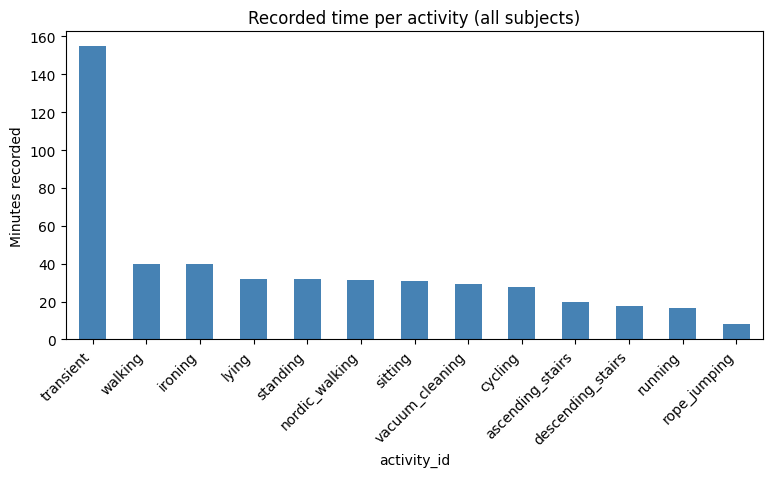

activity_id
transient            154.9
walking               39.8
ironing               39.8
lying                 32.1
standing              31.7
nordic_walking        31.4
sitting               30.9
vacuum_cleaning       29.2
cycling               27.4
ascending_stairs      19.5
descending_stairs     17.5
running               16.4
rope_jumping           8.2
Name: count, dtype: float64


In [5]:
counts = raw["activity_id"].map(ACTIVITY_MAP).value_counts()
minutes = counts / 100 / 60   # 100 readings per second

plt.figure(figsize=(9, 4))
minutes.plot(kind="bar", color="steelblue")
plt.ylabel("Minutes recorded")
plt.title("Recorded time per activity (all subjects)")
plt.xticks(rotation=45, ha="right")
save_fig("eda_class_distribution.png")
plt.show()
print(minutes.round(1))

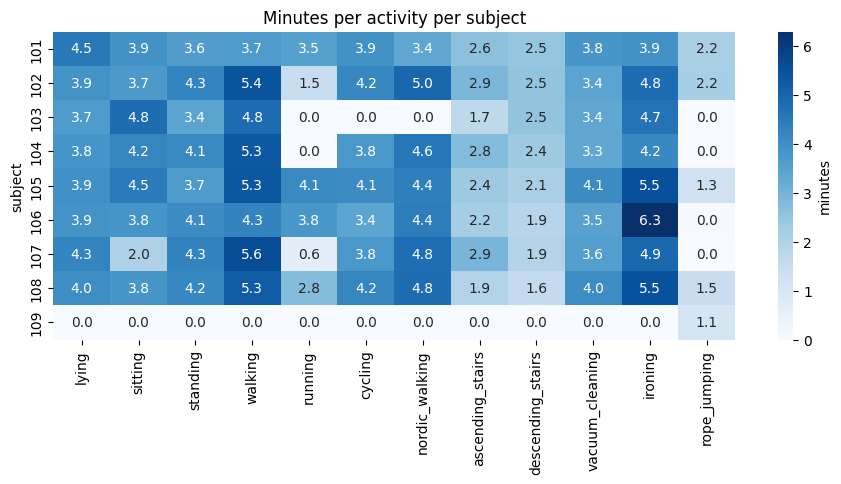

In [6]:
pivot = (raw[raw["activity_id"] != 0]
         .groupby(["subject", "activity_id"]).size()
         .unstack(fill_value=0) / 100 / 60)
pivot.columns = [ACTIVITY_MAP[c] for c in pivot.columns]

plt.figure(figsize=(11, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "minutes"})
plt.title("Minutes per activity per subject")
save_fig("eda_subject_activity.png")
plt.show()

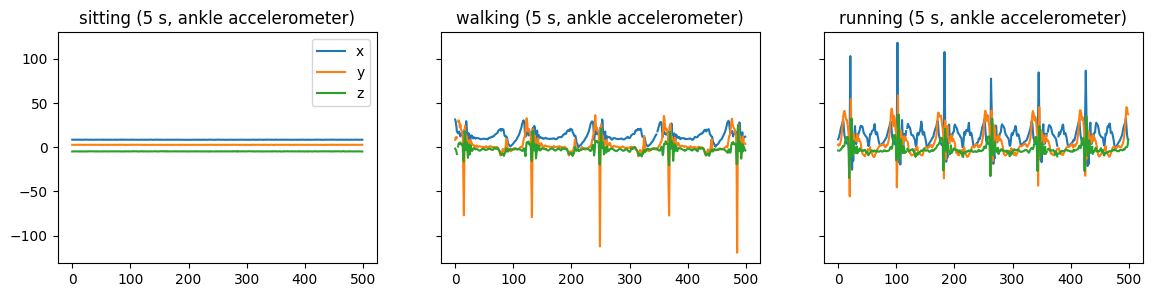

activity_id
standing              0.360000
sitting               0.510000
ironing               0.520000
lying                 0.570000
vacuum_cleaning       2.000000
cycling               4.040000
transient             4.220000
ascending_stairs      8.640000
descending_stairs     8.650000
walking               8.740000
nordic_walking        9.690000
rope_jumping         16.280001
running              16.809999
dtype: float32


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, act in zip(axes, [2, 4, 5]):   # sitting, walking, running
    seg_all = raw[(raw["subject"] == 101) & (raw["activity_id"] == act)]
    mid = len(seg_all) // 2
    seg = seg_all.iloc[mid:mid + 500]
    ax.plot(seg["ankle_acc16_x"].values, label="x")
    ax.plot(seg["ankle_acc16_y"].values, label="y")
    ax.plot(seg["ankle_acc16_z"].values, label="z")
    ax.set_title(ACTIVITY_MAP[act] + " (5 s, ankle accelerometer)")
axes[0].legend()
save_fig("eda_signal_examples.png")
plt.show()

# Sanity check: movement intensity per activity (std of ankle acceleration magnitude)
mag = np.sqrt(raw["ankle_acc16_x"]**2 + raw["ankle_acc16_y"]**2 + raw["ankle_acc16_z"]**2)
print(mag.groupby(raw["activity_id"].map(ACTIVITY_MAP)).std().sort_values().round(2))

### 3.1 What the EDA Shows
- **Size:** the 9 protocol files contain 2,872,533 rows (the 3,850,505 on the UCI page also includes the optional recordings, which are not used here because only some subjects performed them).
- **Missing values:** heart rate is 90.9% empty because it is sampled at ~9 Hz versus 100 Hz for the IMUs, so most rows have no new heart-rate value by design. IMU channels are 0.46% missing, which are genuine sensor dropouts.
- **Class imbalance:** rope jumping has 8.2 minutes of data versus 39.8 for walking and ironing.
- **Uneven subject coverage:** subject 103 did not perform running, cycling, Nordic walking or rope jumping; 104 has no running or rope jumping; 106 and 107 have no rope jumping; subject 109 has only 1.1 minutes, all rope jumping.
- **Signal intensity:** the spread of ankle acceleration separates high-intensity activities (running 16.8, rope jumping 16.3) from still ones (standing 0.36 to lying 0.57). Two groups have near-identical intensity and are expected to be confused: the still postures (lying, sitting, standing, ironing) and walking vs ascending/descending stairs (8.6 to 8.7).

### 3.2 Outliers and Noise
Two checks before cleaning:
1. **Sensor saturation:** the ±16g accelerometer clips at about 157 m/s². Readings at that limit are capped, not exact.
2. **Extreme values:** ankle acceleration magnitude readings more than 6 standard deviations from the mean of their own subject and activity.

In [8]:
G = 9.80665
SAT = 16 * G
acc16_cols = [c for c in raw.columns if "acc16" in c]
labels = raw["activity_id"].map(ACTIVITY_MAP)

near_sat = (raw[acc16_cols].abs() >= 0.98 * SAT).any(axis=1)
print(f"Rows within 2% of the ±16g limit: {int(near_sat.sum())} ({near_sat.mean()*100:.3f}%)")
print(near_sat.groupby(labels).sum().sort_values(ascending=False).head(5), "\n")

acc6_cols = [c for c in raw.columns if "acc6" in c]
near_sat6 = (raw[acc6_cols].abs() >= 0.98 * 6 * G).any(axis=1)
print(f"For comparison, rows within 2% of the ±6g limit: {int(near_sat6.sum())} ({near_sat6.mean()*100:.3f}%)\n")

print("Heart rate range (bpm):", raw["heart_rate"].min(), "to", raw["heart_rate"].max(), "\n")

# mag = ankle acceleration magnitude, computed in the sanity-check cell above
grp = [raw["subject"], raw["activity_id"]]
z = (mag - mag.groupby(grp).transform("mean")) / mag.groupby(grp).transform("std")
extreme = z.abs() > 6
print(f"Ankle readings >6 std from their subject-activity mean: {int(extreme.sum())} ({extreme.mean()*100:.3f}%)")
print((extreme.groupby(labels).mean() * 100).round(3).sort_values(ascending=False).head(6))

Rows within 2% of the ±16g limit: 196 (0.007%)
activity_id
running             111
rope_jumping         58
nordic_walking       11
transient             8
ascending_stairs      7
dtype: int64 

For comparison, rows within 2% of the ±6g limit: 6291 (0.219%)

Heart rate range (bpm): 57.0 to 202.0 

Ankle readings >6 std from their subject-activity mean: 8715 (0.303%)
activity_id
ascending_stairs    0.460
rope_jumping        0.434
lying               0.426
vacuum_cleaning     0.408
ironing             0.407
sitting             0.397
dtype: float64


**Interpretation.** Only 196 rows (0.007%) are within 2% of the ±16g limit, and almost all come from running (111) and rope jumping (58), the two highest-impact activities. These are real foot strikes clipped by the sensor range, not errors, so they are kept (the second, ±6g accelerometer reaches its much lower limit far more often, as the comparison count shows, which is why it is dropped). Heart rate ranges from 57 to 202 bpm, a physiologically plausible range, so no heart-rate values are removed.

About 0.30% of ankle readings are more than 6 standard deviations from their subject-activity mean, spread almost evenly across activities (0.40–0.46% in the most affected ones), including still activities like lying and sitting. In still activities the standard deviation is tiny, so ordinary small movements (shifting position) already exceed 6 std. These spikes reflect normal variation rather than sensor faults, so they are not removed: deleting single samples would break the continuous time series used for windowing, and window-level features (mean, percentiles) and the CNN's pooling layers are robust to isolated spikes. No low-pass filter is applied; averaging over 2.56 s windows already smooths high-frequency noise.

## 4. Preprocessing
Decisions based on the EDA above:
- **Heart rate** is sampled at ~9 Hz vs 100 Hz for the IMUs, so most rows are empty by design. We forward-fill within each subject.
- **IMU dropouts** (~0.5%) are filled by linear interpolation within each subject.
- Filling is done **before** removing transient rows, so values are never interpolated across a gap between two different activities.
- **Dropped columns:** orientation (documented as invalid), the ±6g accelerometer (saturates during high-impact activities like running and rope jumping; the ±16g one does not), and temperature (changes slowly over a session, so a model could use it as a clock instead of learning movement).
- **Dropped rows:** transient activity (label 0) and subject 109 (only 1.1 minutes of data).
- **Outliers:** kept (see Section 3.2): saturated readings and spikes are rare, physically plausible, and handled by window-level features.

In [9]:
drop_cols = [c for c in raw.columns if "orient" in c or "acc6" in c or c.endswith("_temp")]
clean = raw.drop(columns=drop_cols).sort_values(["subject", "timestamp"]).reset_index(drop=True)

SENSOR_COLS = [c for c in clean.columns if c not in ["timestamp", "activity_id", "subject"]]
IMU_SENSOR_COLS = [c for c in SENSOR_COLS if c != "heart_rate"]

clean["heart_rate"] = clean.groupby("subject")["heart_rate"].transform(lambda s: s.ffill().bfill())
clean[IMU_SENSOR_COLS] = clean.groupby("subject")[IMU_SENSOR_COLS].transform(
    lambda s: s.interpolate(limit_direction="both"))

before = len(clean)
clean = clean[(clean["activity_id"] != 0) & (clean["subject"] != 109)].reset_index(drop=True)

print("Rows before filtering:", before)
print("Rows after filtering:", len(clean))
print("Sensor channels kept:", len(SENSOR_COLS), SENSOR_COLS)
print("Remaining NaNs:", int(clean[SENSOR_COLS].isna().sum().sum()))
print("Subjects:", sorted(clean["subject"].unique()))

Rows before filtering: 2872533
Rows after filtering: 1936481
Sensor channels kept: 28 ['heart_rate', 'hand_acc16_x', 'hand_acc16_y', 'hand_acc16_z', 'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z', 'hand_mag_x', 'hand_mag_y', 'hand_mag_z', 'chest_acc16_x', 'chest_acc16_y', 'chest_acc16_z', 'chest_gyro_x', 'chest_gyro_y', 'chest_gyro_z', 'chest_mag_x', 'chest_mag_y', 'chest_mag_z', 'ankle_acc16_x', 'ankle_acc16_y', 'ankle_acc16_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z']
Remaining NaNs: 0
Subjects: [np.int64(101), np.int64(102), np.int64(103), np.int64(104), np.int64(105), np.int64(106), np.int64(107), np.int64(108)]


## 5. Windowing and Subject-wise Split
The model sees short windows of signal, not single readings. One reading at 100 Hz says almost nothing about the activity; a 2.56 s window (256 readings) captures a few steps or pedal strokes.

- Window: 256 readings (2.56 s), step 128 (50% overlap).
- A window never spans two activities, two subjects, or a time gap left by removed transient rows.
- **Split by subject**, not randomly. Overlapping windows from the same person are almost identical, so a random split would put near-copies in train and test and inflate accuracy. Holding out whole people tests whether the model works on someone it has never seen.
- Test: subject 101. Validation: subject 108. Train: the remaining 6. Both held-out subjects performed all 12 activities.

In [10]:
import gc
del raw; gc.collect()

WIN, STEP = 256, 128

ACT_IDS = sorted(clean["activity_id"].unique().astype(int))
ID_TO_IDX = {a: i for i, a in enumerate(ACT_IDS)}
CLASS_NAMES = [ACTIVITY_MAP[a] for a in ACT_IDS]
N_CLASSES = len(CLASS_NAMES)

def make_windows(df, win=WIN, step=STEP, cols=SENSOR_COLS):
    """Cut the signal into fixed-length windows that never cross an activity, subject, or time gap."""
    new_seg = ((df["subject"] != df["subject"].shift()) |
               (df["activity_id"] != df["activity_id"].shift()) |
               (df["timestamp"].diff().abs() > 0.05))
    seg_id = new_seg.cumsum().values
    data = df[cols].values.astype(np.float32)
    acts = df["activity_id"].values.astype(int)
    subs = df["subject"].values.astype(int)

    bounds = np.flatnonzero(np.diff(seg_id)) + 1
    starts, ends = np.r_[0, bounds], np.r_[bounds, len(df)]

    X, y, s = [], [], []
    for a, b in zip(starts, ends):
        for i in range(a, b - win + 1, step):
            X.append(data[i:i + win])
            y.append(ID_TO_IDX[acts[a]])
            s.append(subs[a])
    return np.stack(X), np.array(y), np.array(s)

X_win, y_win, s_win = make_windows(clean)
print("Windows:", X_win.shape, "(windows, timesteps, channels)")

Windows: (14975, 256, 28) (windows, timesteps, channels)


In [11]:
TEST_SUBJECTS, VAL_SUBJECTS = [101], [108]

test_mask = np.isin(s_win, TEST_SUBJECTS)
val_mask = np.isin(s_win, VAL_SUBJECTS)
train_mask = ~(test_mask | val_mask)

X_train_w, y_train = X_win[train_mask], y_win[train_mask]
X_val_w, y_val = X_win[val_mask], y_win[val_mask]
X_test_w, y_test = X_win[test_mask], y_win[test_mask]

split_table = pd.DataFrame({
    "train": np.bincount(y_train, minlength=N_CLASSES),
    "val": np.bincount(y_val, minlength=N_CLASSES),
    "test": np.bincount(y_test, minlength=N_CLASSES)}, index=CLASS_NAMES)
split_table.loc["TOTAL"] = split_table.sum()
split_table

,train,val,test
lying,1096,187,211
sitting,1075,178,182
standing,1109,195,168
walking,1436,245,172
running,466,128,165
cycling,897,198,183
nordic_walking,1079,224,157
ascending_stairs,682,89,121
descending_stairs,609,72,113
vacuum_cleaning,991,188,178


## 6. Feature Engineering (for traditional ML)
Each window is summarised into a fixed-length feature vector:
- **Magnitude channels:** for each sensor location, the overall size of acceleration and rotation, √(x²+y²+z²). This does not depend on how the sensor is rotated on the body, which differs between people.
- **Time-domain statistics** per channel: mean, std, min, max, 25th and 75th percentiles. Mean captures posture (direction of gravity, e.g. lying vs standing); std and range capture movement intensity.
- **Frequency-domain features** on magnitude channels: dominant frequency (step or pedal rate) and spectral energy (intensity). Running and walking differ in rhythm, not only intensity.

Feature names keep the sensor in them (e.g. `ankle_mag_x__std`), so whole sensor groups can be removed in later experiments.

In [12]:
def add_norms(Xw, cols):
    """Append magnitude channels for each accelerometer and gyroscope."""
    extra, names = [], []
    for loc in ["hand", "chest", "ankle"]:
        for sensor in ["acc16", "gyro"]:
            idx = [cols.index(f"{loc}_{sensor}_{a}") for a in "xyz"]
            extra.append(np.linalg.norm(Xw[:, :, idx], axis=2))
            names.append(f"{loc}_{sensor}_norm")
    return np.concatenate([Xw, np.stack(extra, axis=2)], axis=2), cols + names

def extract_features(Xw, cols=SENSOR_COLS, fs=100):
    Xa, names = add_norms(Xw, list(cols))
    feats, fnames = [], []

    stats = {"mean": Xa.mean(1), "std": Xa.std(1), "min": Xa.min(1), "max": Xa.max(1),
             "p25": np.percentile(Xa, 25, axis=1), "p75": np.percentile(Xa, 75, axis=1)}
    for k, v in stats.items():
        feats.append(v)
        fnames += [f"{n}__{k}" for n in names]

    norm_idx = [i for i, n in enumerate(names) if n.endswith("_norm")]
    sig = Xa[:, :, norm_idx] - Xa[:, :, norm_idx].mean(1, keepdims=True)
    power = np.abs(np.fft.rfft(sig, axis=1)) ** 2
    freqs = np.fft.rfftfreq(Xa.shape[1], d=1 / fs)
    feats.append(freqs[power[:, 1:, :].argmax(1) + 1])
    fnames += [f"{names[i]}__dom_freq" for i in norm_idx]
    feats.append(power.sum(1) / Xa.shape[1])
    fnames += [f"{names[i]}__spec_energy" for i in norm_idx]

    return np.concatenate(feats, axis=1).astype(np.float32), fnames

F_train, FEATURE_NAMES = extract_features(X_train_w)
F_val, _ = extract_features(X_val_w)
F_test, _ = extract_features(X_test_w)
print("Feature matrix:", F_train.shape, F_val.shape, F_test.shape)

Feature matrix: (11016, 216) (2027, 216) (1932, 216)


## 7. Experiment Tracking
Every run is logged two ways:
1. **TensorBoard** (`logs/`): metrics and hyperparameters per run (HParams tab), plus training curves for deep learning runs.
2. **CSV** (`results/experiments.csv`): the source of the experiment table in the report.

Models are tuned and compared on the **validation subject (108)**. The **test subject (101)** is used only once, at the end, for the final chosen models.

In [13]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report)
from tensorboard.plugins.hparams import api as hp

WORK = "/kaggle/working"
LOG_DIR = os.path.join(WORK, "logs")
RESULTS_CSV = os.path.join(WORK, "results", "experiments.csv")
MODEL_DIR = os.path.join(WORK, "models")
for d in [LOG_DIR, os.path.dirname(RESULTS_CSV), MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

def compute_metrics(y_true, proba):
    y_pred = proba.argmax(1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro"),
        "roc_auc_ovr": roc_auc_score(y_true, proba, multi_class="ovr", average="macro",
                                     labels=list(range(N_CLASSES))),
    }

def log_experiment(exp_id, model_name, params, metrics, train_time, notes=""):
    row = {"exp_id": exp_id, "model": model_name, "params": json.dumps(params),
           "split": "train=102-107 | val=108 | test=101",
           **{k: round(float(v), 4) for k, v in metrics.items()},
           "train_time_s": round(train_time, 1), "notes": notes}
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", index=False,
                               header=not os.path.exists(RESULTS_CSV))

    hp_params = {k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in params.items()}
    hp_params["model"] = model_name
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, exp_id)).as_default():
        hp.hparams(hp_params, trial_id=exp_id)
        for k, v in metrics.items():
            tf.summary.scalar(f"val/{k}", float(v), step=1)

    print(f"[{exp_id}] {model_name} | val acc={metrics['accuracy']:.4f} "
          f"macro_f1={metrics['macro_f1']:.4f} auc={metrics['roc_auc_ovr']:.4f} | {train_time:.1f}s")

# Start clean each time the notebook is run top-to-bottom
if os.path.exists(RESULTS_CSV):
    os.remove(RESULTS_CSV)

## 8. Traditional Machine Learning

### 8.1 Baselines
Four algorithms with different assumptions:
- **Logistic Regression:** linear decision boundaries; a simple, interpretable reference point.
- **Random Forest:** many decision trees on random subsets; handles non-linear patterns and is hard to overfit badly.
- **Histogram Gradient Boosting:** trees built one after another, each correcting the last; often the strongest on tabular features.
- **SVM (RBF kernel):** finds non-linear boundaries with maximum margin; sensitive to feature scaling.

All use `class_weight="balanced"` because rope jumping has far fewer windows than the other classes. Scale-sensitive models (LR, SVM) get a `StandardScaler` fitted on training data only.

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

ml_models = {}

def run_sklearn(exp_id, name, model, params, X_tr=None, X_va=None, notes=""):
    X_tr = F_train if X_tr is None else X_tr
    X_va = F_val if X_va is None else X_va
    t0 = time.time()
    model.fit(X_tr, y_train)
    train_time = time.time() - t0
    metrics = compute_metrics(y_val, model.predict_proba(X_va))
    log_experiment(exp_id, name, params, metrics, train_time, notes)
    ml_models[exp_id] = model
    return model, metrics

In [15]:
run_sklearn("ML-01", "LogisticRegression",
            make_pipeline(StandardScaler(), LogisticRegression(
                C=1.0, max_iter=3000, class_weight="balanced", random_state=SEED)),
            {"C": 1.0, "scaler": "standard"}, notes="Linear baseline")

run_sklearn("ML-02", "RandomForest",
            RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   n_jobs=-1, random_state=SEED),
            {"n_estimators": 300, "max_depth": "None"}, notes="Default RF")

run_sklearn("ML-03", "HistGradientBoosting",
            HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                           class_weight="balanced", random_state=SEED),
            {"max_iter": 300, "learning_rate": 0.1}, notes="Default boosting")

run_sklearn("ML-04", "SVM_RBF",
            make_pipeline(StandardScaler(), SVC(
                C=10, gamma="scale", probability=True,
                class_weight="balanced", random_state=SEED)),
            {"C": 10, "gamma": "scale", "kernel": "rbf"}, notes="Kernel baseline")

pd.read_csv(RESULTS_CSV)[["exp_id", "model", "accuracy", "macro_f1", "roc_auc_ovr", "train_time_s"]]

I0000 00:00:1792075234.498540      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792075234.504763      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[ML-01] LogisticRegression | val acc=0.5802 macro_f1=0.5405 auc=0.9592 | 7.0s
[ML-02] RandomForest | val acc=0.7632 macro_f1=0.7632 auc=0.9910 | 20.5s
[ML-03] HistGradientBoosting | val acc=0.7252 macro_f1=0.6851 auc=0.9808 | 13.5s
[ML-04] SVM_RBF | val acc=0.5925 macro_f1=0.5213 auc=0.9556 | 13.7s


,exp_id,model,accuracy,macro_f1,roc_auc_ovr,train_time_s
0,ML-01,LogisticRegression,0.5802,0.5405,0.9592,7.0
1,ML-02,RandomForest,0.7632,0.7632,0.9910,20.5
2,ML-03,HistGradientBoosting,0.7252,0.6851,0.9808,13.5
3,ML-04,SVM_RBF,0.5925,0.5213,0.9556,13.7


### 8.2 Feature Selection by Sensor Group
LR and SVM performed much worse than the tree models. Hypothesis: heart rate depends on each person's fitness, and the magnetometer depends on surroundings, so these features help on training subjects but do not transfer to a new person. We remove each group and compare on the validation subject.

In [16]:
FEATURE_SETS = {
    "all": [],
    "no_mag": ["_mag_"],
    "no_hr": ["heart_rate"],
    "no_mag_no_hr": ["_mag_", "heart_rate"],
}

def feature_mask(set_name):
    excl = FEATURE_SETS[set_name]
    return np.array([not any(e in n for e in excl) for n in FEATURE_NAMES])

for k in FEATURE_SETS:
    print(k, int(feature_mask(k).sum()), "features")

def make_rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  n_jobs=-1, random_state=SEED)

def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(
        C=1.0, max_iter=3000, class_weight="balanced", random_state=SEED))

def make_svm():
    return make_pipeline(StandardScaler(), SVC(
        C=10, gamma="scale", probability=True, class_weight="balanced", random_state=SEED))

exp_plan = [
    ("ML-05", "RandomForest", make_rf, "no_mag"),
    ("ML-06", "RandomForest", make_rf, "no_hr"),
    ("ML-07", "RandomForest", make_rf, "no_mag_no_hr"),
    ("ML-08", "LogisticRegression", make_lr, "no_mag_no_hr"),
    ("ML-09", "SVM_RBF", make_svm, "no_mag_no_hr"),
]
for exp_id, name, factory, fset in exp_plan:
    m = feature_mask(fset)
    run_sklearn(exp_id, name, factory(), {"feature_set": fset, "n_features": int(m.sum()),
                 "base_config": {"RandomForest": "ML-02", "LogisticRegression": "ML-01", "SVM_RBF": "ML-04"}[name]},
                X_tr=F_train[:, m], X_va=F_val[:, m], notes=f"Ablation: {fset}")

pd.read_csv(RESULTS_CSV)[["exp_id", "model", "params", "accuracy", "macro_f1", "roc_auc_ovr"]]

all 216 features
no_mag 162 features
no_hr 210 features
no_mag_no_hr 156 features
[ML-05] RandomForest | val acc=0.8342 macro_f1=0.8123 auc=0.9923 | 18.1s
[ML-06] RandomForest | val acc=0.7242 macro_f1=0.7196 auc=0.9811 | 20.7s
[ML-07] RandomForest | val acc=0.8170 macro_f1=0.7980 auc=0.9837 | 18.0s
[ML-08] LogisticRegression | val acc=0.5886 macro_f1=0.5636 auc=0.9452 | 9.7s
[ML-09] SVM_RBF | val acc=0.5964 macro_f1=0.5162 auc=0.9512 | 13.9s


,exp_id,model,params,accuracy,macro_f1,roc_auc_ovr
0,ML-01,LogisticRegression,"{""C"": 1.0, ""scaler"": ""standard""}",0.5802,0.5405,0.9592
1,ML-02,RandomForest,"{""n_estimators"": 300, ""max_depth"": ""None""}",0.7632,0.7632,0.9910
2,ML-03,HistGradientBoosting,"{""max_iter"": 300, ""learning_rate"": 0.1}",0.7252,0.6851,0.9808
3,ML-04,SVM_RBF,"{""C"": 10, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.5925,0.5213,0.9556
4,ML-05,RandomForest,"{""feature_set"": ""no_mag"", ""n_features"": 162, ""...",0.8342,0.8123,0.9923
5,ML-06,RandomForest,"{""feature_set"": ""no_hr"", ""n_features"": 210, ""b...",0.7242,0.7196,0.9811
6,ML-07,RandomForest,"{""feature_set"": ""no_mag_no_hr"", ""n_features"": ...",0.8170,0.7980,0.9837
7,ML-08,LogisticRegression,"{""feature_set"": ""no_mag_no_hr"", ""n_features"": ...",0.5886,0.5636,0.9452
8,ML-09,SVM_RBF,"{""feature_set"": ""no_mag_no_hr"", ""n_features"": ...",0.5964,0.5162,0.9512


### 8.3 Results of Feature Selection
Removing magnetometer features improved Random Forest (macro F1 0.763 → 0.812), supporting the idea that magnetometer readings reflect surroundings rather than movement. Removing heart rate reduced performance (0.763 → 0.720), so heart rate carries useful intensity information. LR and SVM barely changed, so their weakness is not caused by these features. From here on, the **no_mag** feature set is used.

### 8.4 Hyperparameter Tuning
A single validation subject gives a noisy estimate, so tuning uses **GroupKFold cross-validation on the training subjects**: each fold holds out different people, never splitting one person across folds. Search is randomised over tree depth, leaf size, features per split, and class weighting.

In [17]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

FSET = "no_mag"
m_best = feature_mask(FSET)
F_train_s, F_val_s, F_test_s = F_train[:, m_best], F_val[:, m_best], F_test[:, m_best]
FEATURE_NAMES_S = [n for n, keep in zip(FEATURE_NAMES, m_best) if keep]
groups_train = s_win[train_mask]

# Boosting on the improved feature set, for a fair comparison with RF
run_sklearn("ML-10", "HistGradientBoosting",
            HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                           class_weight="balanced", random_state=SEED),
            {"feature_set": FSET, "max_iter": 300, "learning_rate": 0.1},
            X_tr=F_train_s, X_va=F_val_s, notes="Boosting on no_mag features")

param_dist = {
    "n_estimators": [300, 500],
    "max_depth": [None, 15, 25],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2", 0.3],
    "class_weight": ["balanced", "balanced_subsample"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=SEED),
    param_dist, n_iter=12, scoring="f1_macro",
    cv=GroupKFold(n_splits=3), random_state=SEED, verbose=1, refit=True)

t0 = time.time()
search.fit(F_train_s, y_train, groups=groups_train)
tune_time = time.time() - t0

best_rf = search.best_estimator_
metrics = compute_metrics(y_val, best_rf.predict_proba(F_val_s))
log_experiment("ML-11", "RandomForest_tuned",
               {"feature_set": FSET, **search.best_params_}, metrics, tune_time,
               notes=f"RandomizedSearch 12 configs, GroupKFold(3) CV macro F1={search.best_score_:.4f}")
ml_models["ML-11"] = best_rf

cv_table = (pd.DataFrame(search.cv_results_)
            [["params", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score"))
cv_table.to_csv(os.path.join(WORK, "results", "rf_tuning_cv.csv"), index=False)
import joblib
joblib.dump(best_rf, os.path.join(MODEL_DIR, "best_random_forest.joblib"))
json.dump({"feature_set": FSET, "feature_names": FEATURE_NAMES_S, "classes": CLASS_NAMES},
          open(os.path.join(MODEL_DIR, "rf_metadata.json"), "w"))
print("Saved RF model to", MODEL_DIR)
print("Best params:", search.best_params_)
cv_table.head(5)

[ML-10] HistGradientBoosting | val acc=0.8495 macro_f1=0.8191 auc=0.9881 | 9.9s
Fitting 3 folds for each of 12 candidates, totalling 36 fits
[ML-11] RandomForest_tuned | val acc=0.9132 macro_f1=0.8969 auc=0.9916 | 662.9s
Saved RF model to /kaggle/working/models
Best params: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced_subsample'}


,params,mean_test_score,std_test_score,rank_test_score
10,"{'n_estimators': 500, 'min_samples_leaf': 2, '...",0.845186,0.045054,1
1,"{'n_estimators': 300, 'min_samples_leaf': 5, '...",0.845099,0.042932,2
9,"{'n_estimators': 500, 'min_samples_leaf': 5, '...",0.844369,0.047175,3
3,"{'n_estimators': 500, 'min_samples_leaf': 5, '...",0.843914,0.049151,4
4,"{'n_estimators': 300, 'min_samples_leaf': 2, '...",0.843262,0.046757,5


### 8.5 Tuning Result
The tuned Random Forest (ML-11) reaches macro F1 0.897 on the validation subject, up from 0.812 (ML-05). The search chose shallower trees (`max_depth=15`), at least 2 windows per leaf, and fewer features per split (`log2`); all three make individual trees simpler and more random, which reduces overfitting to the training people.

The cross-validation table shows the top five configurations within 0.003 macro F1 of each other, while the spread across held-out subjects is about ±0.045. The exact settings matter far less than *which person* is being tested, so a larger search would mostly chase noise. Validation (0.897) is also higher than the cross-validation average (0.845), which suggests subject 108 is easier than average. This is one reason the final comparison is repeated across all subjects in Section 10.1.

## 9. Deep Learning

### 9.1 Input Pipeline
- **Raw windows** (256 timesteps × 19 channels) for CNN/LSTM models: magnetometer channels removed, as in Section 8.3.
- **Engineered features** (162) for an MLP, so DL can also be compared on the same input as traditional ML.
- Each channel is standardised using the **training set's** mean and std only.
- Data is fed with the **`tf.data` API**: shuffle, optional augmentation, batching, and prefetching to the GPU.
- Class weights (same balanced scheme as Section 8) are passed to training.
- **Early stopping** on validation loss (patience 8) restores the best weights. TensorBoard logs every epoch.

In [18]:
from tensorflow.keras import layers, models, regularizers
from sklearn.utils.class_weight import compute_class_weight

DL_CHANNELS = [c for c in SENSOR_COLS if "_mag_" not in c]
ch_idx = [SENSOR_COLS.index(c) for c in DL_CHANNELS]

mu = X_train_w[:, :, ch_idx].mean(axis=(0, 1), keepdims=True)
sd = X_train_w[:, :, ch_idx].std(axis=(0, 1), keepdims=True) + 1e-8
X_tr_dl = ((X_train_w[:, :, ch_idx] - mu) / sd).astype(np.float32)
X_va_dl = ((X_val_w[:, :, ch_idx] - mu) / sd).astype(np.float32)
X_te_dl = ((X_test_w[:, :, ch_idx] - mu) / sd).astype(np.float32)
np.savez(os.path.join(MODEL_DIR, "dl_norm_stats.npz"), mean=mu, std=sd, channels=np.array(DL_CHANNELS))

feat_scaler = StandardScaler().fit(F_train_s)
Ftr_dl, Fva_dl, Fte_dl = [feat_scaler.transform(a).astype(np.float32) for a in (F_train_s, F_val_s, F_test_s)]

cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CLASS_WEIGHTS = dict(enumerate(cw))

BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE

def augment(x, y):
    """Random per-channel scaling (±10%) and small noise: mimics differences in sensor fit between people."""
    scale = tf.random.uniform([1, tf.shape(x)[-1]], 0.9, 1.1)
    noise = tf.random.normal(tf.shape(x), stddev=0.05)
    return x * scale + noise, y

def make_ds(X, y, training=False, augment_data=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
        if augment_data:
            ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

print("Raw input:", X_tr_dl.shape, "| Feature input:", Ftr_dl.shape)
print("GPU:", tf.config.list_physical_devices("GPU"))

Raw input: (11016, 256, 19) | Feature input: (11016, 162)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [19]:
def build_mlp(n_in, units=(256, 128), dropout=0.3):
    m = models.Sequential([layers.Input((n_in,))])
    for u in units:
        m.add(layers.Dense(u, activation="relu"))
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(N_CLASSES, activation="softmax"))
    return m

def build_cnn(input_shape, filters=(64, 64, 128), kernel=5, dropout=0.3, l2=0.0, batchnorm=False):
    reg = regularizers.l2(l2) if l2 else None
    m = models.Sequential([layers.Input(input_shape)])
    for i, f in enumerate(filters):
        m.add(layers.Conv1D(f, kernel, padding="same", kernel_regularizer=reg))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation("relu"))
        if i < len(filters) - 1:
            m.add(layers.MaxPooling1D(2))
    m.add(layers.GlobalAveragePooling1D())
    m.add(layers.Dropout(dropout))
    m.add(layers.Dense(64, activation="relu", kernel_regularizer=reg))
    m.add(layers.Dropout(dropout))
    m.add(layers.Dense(N_CLASSES, activation="softmax"))
    return m

def build_cnn_lstm(input_shape, filters=64, lstm_units=64, dropout=0.3):
    """Functional API: convolutions extract short local patterns, the LSTM models how they change over the window."""
    inp = layers.Input(input_shape)
    x = layers.Conv1D(filters, 5, padding="same", activation="relu")(inp)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(filters, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.LSTM(lstm_units)(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return models.Model(inp, out)

dl_models, histories = {}, {}

def plot_learning_curve(hist, exp_id, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
    ax[0].set_title(f"{exp_id} loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="val")
    ax[1].set_title(f"{exp_id} accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    fig.suptitle(title)
    save_fig(f"lc_{exp_id}.png")
    plt.show()

def run_keras(exp_id, name, build_fn, params, train_ds, val_ds, X_va, lr=1e-3, epochs=40, notes=""):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
           tf.keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, exp_id))]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=CLASS_WEIGHTS, callbacks=cbs, verbose=0)
    train_time = time.time() - t0
    metrics = compute_metrics(y_val, model.predict(X_va, verbose=0))
    full_params = {**params, "lr": lr, "batch": BATCH,
                   "epochs_run": len(hist.history["loss"]), "params_count": model.count_params()}
    log_experiment(exp_id, name, full_params, metrics, train_time, notes)
    dl_models[exp_id], histories[exp_id] = model, hist
    plot_learning_curve(hist, exp_id, f"{name} ({notes})")
    return model, metrics

### 9.2 Baselines: MLP on features vs 1D CNN on raw signal
DL-01 uses the same engineered features as Random Forest, so any difference comes from the model. DL-02 learns its own features directly from the raw signal.

I0000 00:00:1792076047.615739     141 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


[DL-01] MLP_features | val acc=0.6986 macro_f1=0.6823 auc=0.9786 | 10.7s


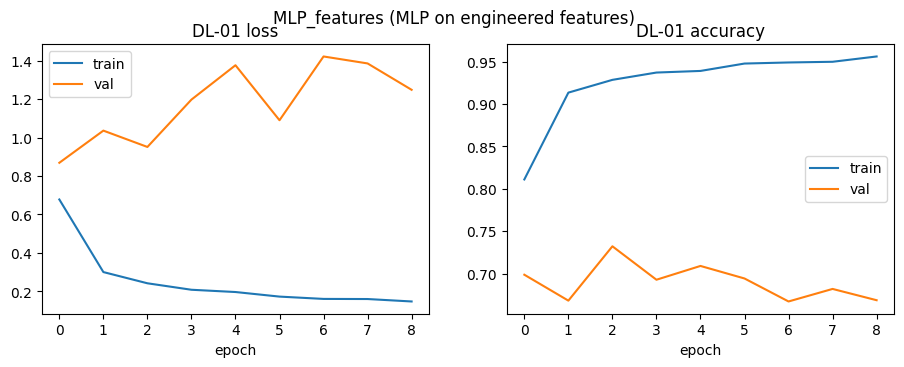

[DL-02] CNN1D | val acc=0.4159 macro_f1=0.3515 auc=0.8400 | 17.4s


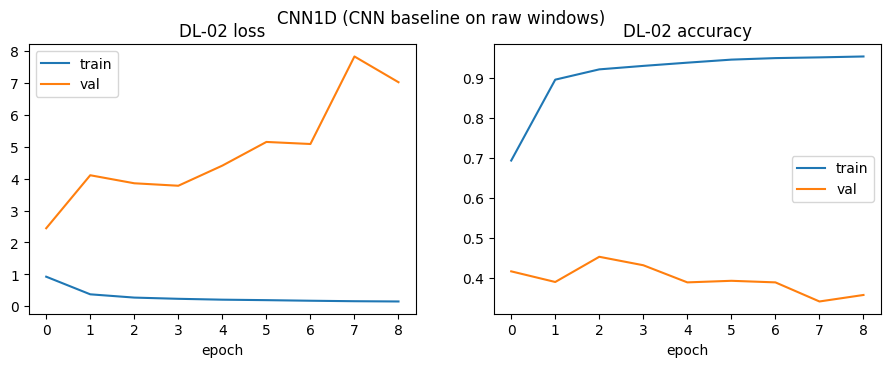

In [20]:
ds_tr_feat = make_ds(Ftr_dl, y_train, training=True)
ds_va_feat = make_ds(Fva_dl, y_val)
ds_tr_raw = make_ds(X_tr_dl, y_train, training=True)
ds_va_raw = make_ds(X_va_dl, y_val)
IN_SHAPE = X_tr_dl.shape[1:]

_ = run_keras("DL-01", "MLP_features", lambda: build_mlp(Ftr_dl.shape[1]),
          {"input": "features_no_mag", "units": "256-128", "dropout": 0.3},
          ds_tr_feat, ds_va_feat, Fva_dl, notes="MLP on engineered features")

_ = run_keras("DL-02", "CNN1D", lambda: build_cnn(IN_SHAPE),
          {"input": "raw_19ch", "filters": "64-64-128", "kernel": 5, "dropout": 0.3},
          ds_tr_raw, ds_va_raw, X_va_dl, notes="CNN baseline on raw windows")

### 9.3 Diagnosing Overfitting
Both baselines overfit from the first epoch: training accuracy reaches ~90% while validation loss rises continuously. The MLP uses the same features as Random Forest yet scores far lower (0.68 vs 0.90 macro F1), so the gap comes from the model, not the input. With only six training subjects, the networks memorise person-specific signal characteristics.

Three experiments test possible fixes, one idea each:
- **DL-03:** remove the heart-rate channel (does the CNN memorise each person's heart-rate level?)
- **DL-04:** data augmentation through `tf.data` (random per-channel scaling ±10% and noise, simulating differences in sensor fit between people)
- **DL-05:** augmentation plus BatchNorm, L2 (1e-3) and dropout 0.5

[DL-03] CNN1D | val acc=0.3532 macro_f1=0.3158 auc=0.7858 | 14.9s


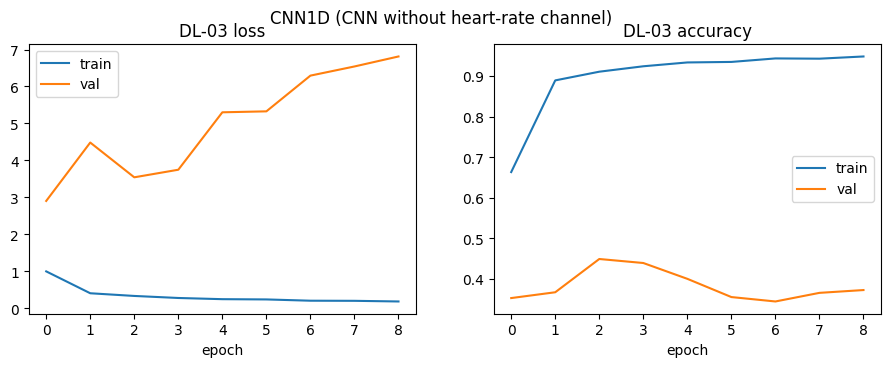

[DL-04] CNN1D | val acc=0.4420 macro_f1=0.3794 auc=0.8395 | 17.5s


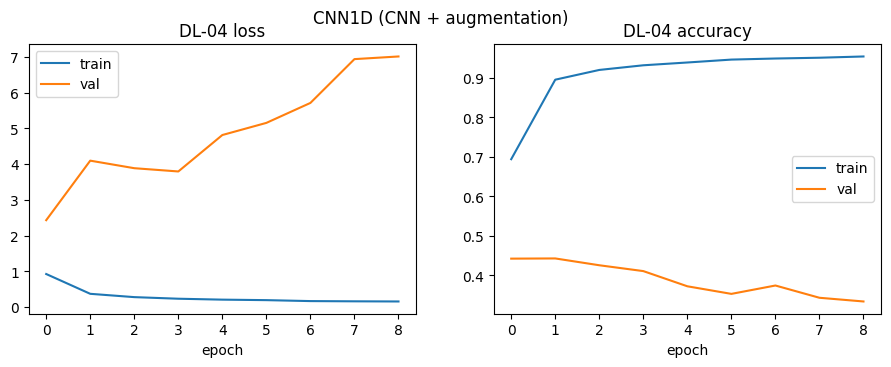

[DL-05] CNN1D_regularised | val acc=0.4662 macro_f1=0.4097 auc=0.9413 | 22.0s


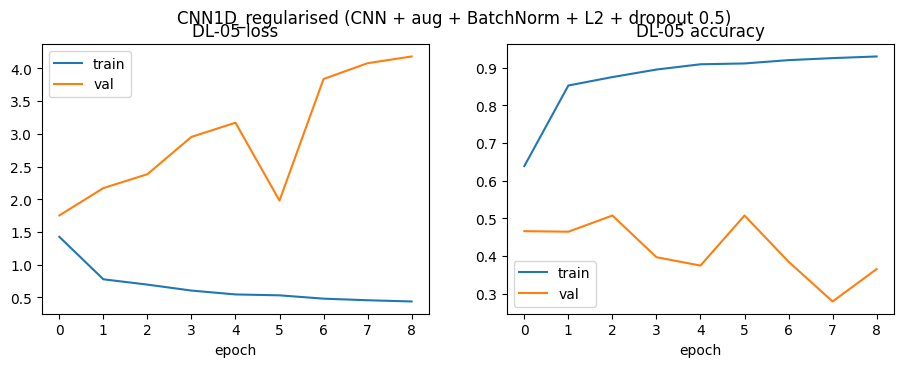

In [21]:
NO_HR = [i for i, c in enumerate(DL_CHANNELS) if c != "heart_rate"]
ds_tr_raw_nohr = make_ds(X_tr_dl[:, :, NO_HR], y_train, training=True)
ds_va_raw_nohr = make_ds(X_va_dl[:, :, NO_HR], y_val)

_ = run_keras("DL-03", "CNN1D", lambda: build_cnn((WIN, len(NO_HR))),
              {"input": "raw_18ch_no_hr", "filters": "64-64-128", "kernel": 5, "dropout": 0.3},
              ds_tr_raw_nohr, ds_va_raw_nohr, X_va_dl[:, :, NO_HR],
              notes="CNN without heart-rate channel")

ds_tr_raw_aug = make_ds(X_tr_dl, y_train, training=True, augment_data=True)

_ = run_keras("DL-04", "CNN1D", lambda: build_cnn(IN_SHAPE),
              {"input": "raw_19ch", "filters": "64-64-128", "kernel": 5, "dropout": 0.3, "augment": True},
              ds_tr_raw_aug, ds_va_raw, X_va_dl,
              notes="CNN + augmentation")

_ = run_keras("DL-05", "CNN1D_regularised",
              lambda: build_cnn(IN_SHAPE, dropout=0.5, l2=1e-3, batchnorm=True),
              {"input": "raw_19ch", "filters": "64-64-128", "kernel": 5, "dropout": 0.5,
               "l2": 1e-3, "batchnorm": True, "augment": True},
              ds_tr_raw_aug, ds_va_raw, X_va_dl,
              notes="CNN + aug + BatchNorm + L2 + dropout 0.5")

### 9.4 Why Regularisation Did Not Help
Removing heart rate, augmentation, and heavy regularisation all failed (macro F1 roughly 0.3–0.35, no better than the DL-02 baseline). Training accuracy stays high while validation stays low regardless of regularisation strength, which points to a **systematic difference between subjects** (distribution shift) rather than variance alone. A likely cause is sensor orientation: raw x/y/z axes depend on how each sensor was strapped on, while Random Forest features include orientation-independent magnitudes. The diagnostic below compares each subject's average accelerometer reading per axis while standing still.

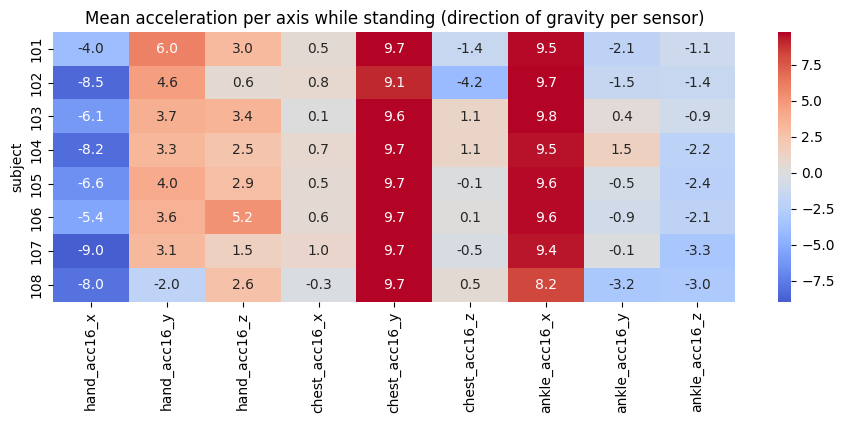

In [22]:
stand = clean[clean["activity_id"] == 3]
acc_cols = [f"{loc}_acc16_{a}" for loc in ["hand", "chest", "ankle"] for a in "xyz"]
diag = stand.groupby("subject")[acc_cols].mean()

plt.figure(figsize=(11, 3.5))
sns.heatmap(diag, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Mean acceleration per axis while standing (direction of gravity per sensor)")
save_fig("diag_sensor_orientation.png")
plt.show()

In [ ]:
def norm_channels(Xw):
    Xa, _ = add_norms(Xw, list(SENSOR_COLS))
    return Xa[:, :, -6:]   # acc and gyro magnitudes for hand, chest, ankle

N_tr, N_va, N_te = norm_channels(X_train_w), norm_channels(X_val_w), norm_channels(X_test_w)
nmu, nsd = N_tr.mean((0, 1), keepdims=True), N_tr.std((0, 1), keepdims=True) + 1e-8
N_tr, N_va, N_te = [((a - nmu) / nsd).astype(np.float32) for a in (N_tr, N_va, N_te)]
np.savez(os.path.join(MODEL_DIR, "dl_norm_channel_stats.npz"), mean=nmu, std=nsd)

hr = [DL_CHANNELS.index("heart_rate")]
XN_tr, XN_va, XN_te = [np.concatenate([n, x[:, :, hr]], axis=2)
                       for n, x in ((N_tr, X_tr_dl), (N_va, X_va_dl), (N_te, X_te_dl))]
XC_tr, XC_va, XC_te = [np.concatenate([x, n], axis=2)
                       for x, n in ((X_tr_dl, N_tr), (X_va_dl, N_va), (X_te_dl, N_te))]

AXIS_MASK = tf.constant([0.0 if c == "heart_rate" else 1.0 for c in DL_CHANNELS] + [0.0] * 6)

def augment_flip(x, y):
    """Scaling + noise, then random sign flip per axis channel (magnitudes and heart rate untouched)."""
    x, y = augment(x, y)
    flip = tf.cast(tf.random.uniform([1, tf.shape(x)[-1]]) < 0.5, tf.float32)
    return x * (1.0 - 2.0 * flip * AXIS_MASK), y

def make_ds_fn(X, y, training=False, aug_fn=None):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
        if aug_fn is not None:
            ds = ds.map(aug_fn, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

_ = run_keras("DL-06", "CNN1D", lambda: build_cnn(XN_tr.shape[1:]),
              {"input": "norms_6ch+hr", "filters": "64-64-128", "kernel": 5, "dropout": 0.3},
              make_ds_fn(XN_tr, y_train, True), make_ds_fn(XN_va, y_val), XN_va,
              notes="CNN on orientation-free magnitudes + HR")

_ = run_keras("DL-07", "CNN1D", lambda: build_cnn(XC_tr.shape[1:]),
              {"input": "raw_19ch+norms_6ch", "filters": "64-64-128", "kernel": 5, "dropout": 0.3,
               "augment": "scale+noise+axis_flip"},
              make_ds_fn(XC_tr, y_train, True, augment_flip), make_ds_fn(XC_va, y_val), XC_va,
              notes="CNN raw+magnitudes with axis-flip augmentation")

_ = run_keras("DL-08", "MLP_features", lambda: build_mlp(Ftr_dl.shape[1], dropout=0.5),
              {"input": "features_no_mag", "units": "256-128", "dropout": 0.5},
              ds_tr_feat, ds_va_feat, Fva_dl, lr=3e-4,
              notes="MLP with dropout 0.5 and lower LR")

### 9.5 Orientation-Independent Inputs
The diagnostic confirms the orientation problem: subject 108's wrist sensor reads −2.0 on the y-axis while standing, versus +3 to +6 for every training subject. The chest sensor is consistent across people.

Using only magnitude channels plus heart rate (DL-06) removed the overfitting: training and validation curves now track each other, and macro F1 rose from ~0.35 to ~0.85. Changing the **input representation** fixed what five regularisation-style changes could not.

Final DL experiments on this input:
- **DL-09:** CNN-LSTM (Functional API): convolutions capture short patterns, the LSTM models how they unfold over the window.
- **DL-10:** DL-06 with a lower learning rate (3e-4) to reduce the noisy validation loss.

[DL-09] CNN_LSTM | val acc=0.8599 macro_f1=0.8450 auc=0.9909 | 36.9s


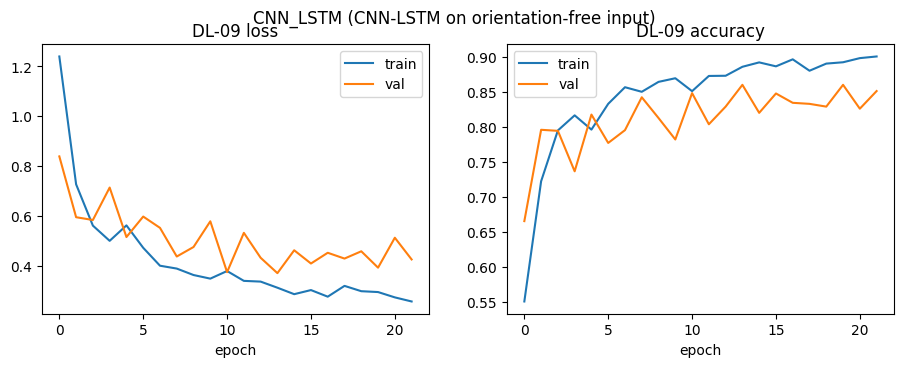

[DL-10] CNN1D | val acc=0.8569 macro_f1=0.8393 auc=0.9876 | 29.8s


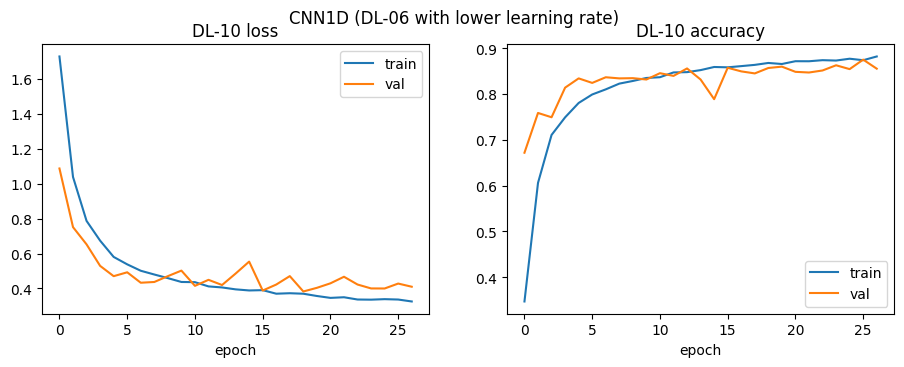

In [24]:
_ = run_keras("DL-09", "CNN_LSTM", lambda: build_cnn_lstm(XN_tr.shape[1:]),
              {"input": "norms_6ch+hr", "filters": 64, "lstm_units": 64, "dropout": 0.3, "api": "functional"},
              make_ds_fn(XN_tr, y_train, True), make_ds_fn(XN_va, y_val), XN_va,
              notes="CNN-LSTM on orientation-free input")

_ = run_keras("DL-10", "CNN1D", lambda: build_cnn(XN_tr.shape[1:]),
              {"input": "norms_6ch+hr", "filters": "64-64-128", "kernel": 5, "dropout": 0.3},
              make_ds_fn(XN_tr, y_train, True), make_ds_fn(XN_va, y_val), XN_va, lr=3e-4,
              notes="DL-06 with lower learning rate")

### 9.6 CNN-LSTM, Learning Rate, and Tuning the CNN
The CNN-LSTM (DL-09) did not improve on the plain CNN (DL-06) and took longer to train. A 2.56 s window holds only a few movement cycles, and stacked convolutions with pooling already cover most of it, so there is little long-range order left for the LSTM to model. Lowering the learning rate (DL-10) gave similar macro F1 but smoother learning curves, with training and validation tracking each other.

So far the CNN has had far less tuning than the Random Forest (12 configurations with cross-validation). To make the comparison fair, DL-11 to DL-14 change one setting at a time from DL-06: kernel size (3 vs 9: shorter vs longer patterns in time), network size (fewer filters: less capacity, lower variance), and dropout. Differences of about 0.02 macro F1 between single runs are within normal run-to-run variation on GPU and should not be over-read.

[DL-11] CNN1D | val acc=0.8777 macro_f1=0.8735 auc=0.9907 | 35.1s


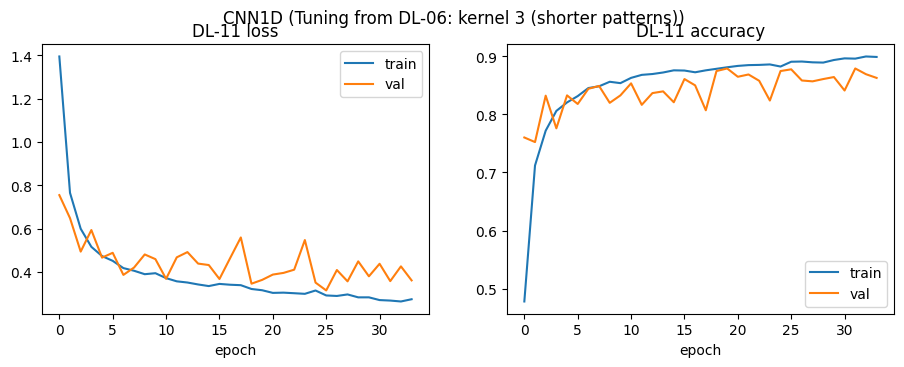

2026-10-15 14:58:46.312058: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-15 14:58:46.501115: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-15 14:58:47.274007: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-15 14:58:47.638570: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


[DL-12] CNN1D | val acc=0.8722 macro_f1=0.8650 auc=0.9905 | 28.7s


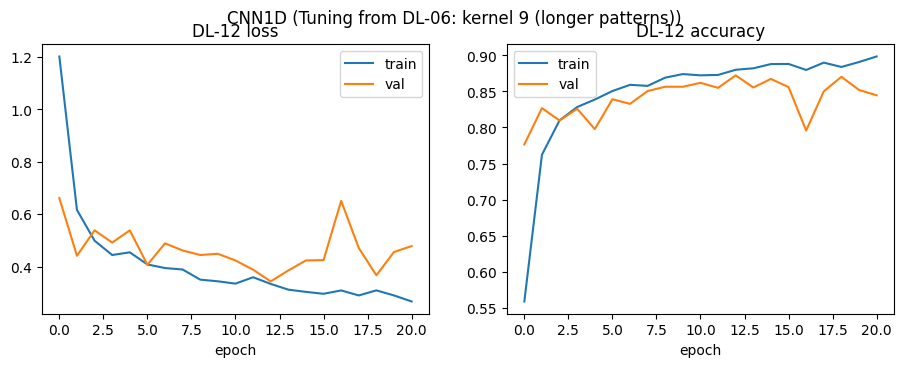

[DL-13] CNN1D | val acc=0.8569 macro_f1=0.8421 auc=0.9893 | 32.5s


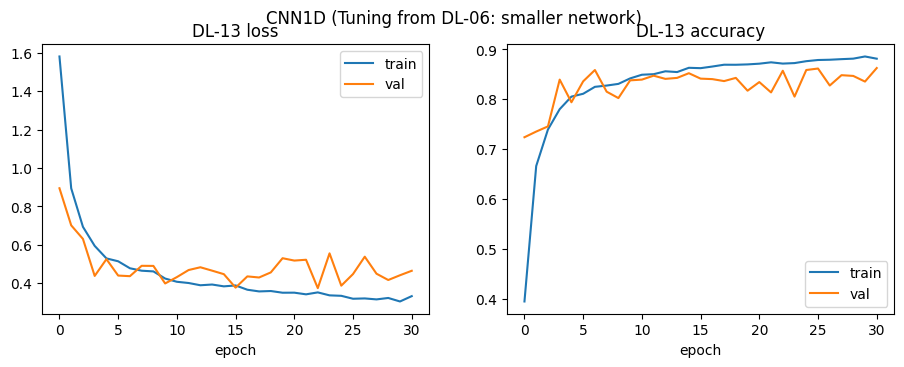

[DL-14] CNN1D | val acc=0.8767 macro_f1=0.8703 auc=0.9927 | 24.5s


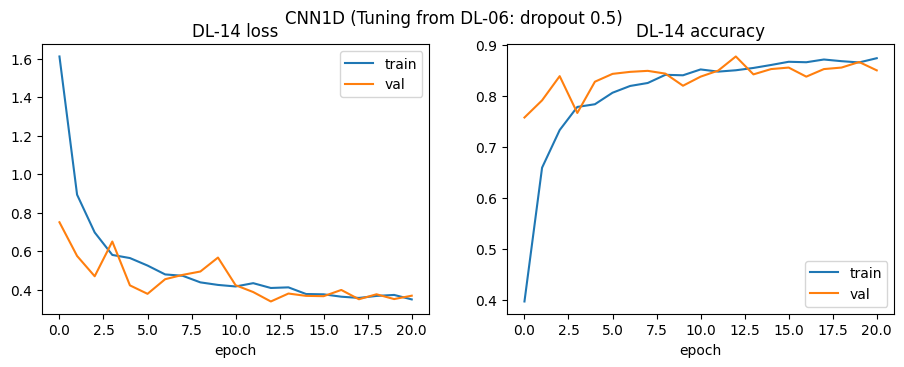

In [25]:
base_cfg = {"filters": (64, 64, 128), "kernel": 5, "dropout": 0.3}
sweep = [
    ("DL-11", {"kernel": 3}, "kernel 3 (shorter patterns)"),
    ("DL-12", {"kernel": 9}, "kernel 9 (longer patterns)"),
    ("DL-13", {"filters": (32, 32, 64)}, "smaller network"),
    ("DL-14", {"dropout": 0.5}, "dropout 0.5"),
]
ds_tr_n, ds_va_n = make_ds_fn(XN_tr, y_train, True), make_ds_fn(XN_va, y_val)

for exp_id, change, note in sweep:
    cfg = {**base_cfg, **change}
    _ = run_keras(exp_id, "CNN1D",
                  lambda cfg=cfg: build_cnn(XN_tr.shape[1:], filters=cfg["filters"],
                                            kernel=cfg["kernel"], dropout=cfg["dropout"]),
                  {"input": "norms_6ch+hr", "filters": "-".join(map(str, cfg["filters"])),
                   "kernel": cfg["kernel"], "dropout": cfg["dropout"]},
                  ds_tr_n, ds_va_n, XN_va, notes=f"Tuning from DL-06: {note}")

### 9.7 Tuning Result
All four changes land within about ±0.015 macro F1 of DL-06, which is the size of normal run-to-run variation on GPU. The best configuration on validation is used for the final evaluation, but no single setting (kernel size, network size, dropout) changes the CNN's performance in a meaningful way. Once the input representation is fixed, the CNN is limited by what the input contains, not by its hyperparameters.

### 9.8 Separating Model from Input (ML-12)
The tuned Random Forest uses features that include the direction of gravity (per-axis means), while the best CNN sees only orientation-free magnitudes and heart rate. So "Random Forest vs CNN" is partly "posture information vs no posture information". To separate the two, ML-12 trains the same tuned Random Forest configuration on **only the orientation-free features** (statistics of the six magnitude channels and heart rate), which is the same information the CNN receives.

In [26]:
from sklearn.base import clone
ORI_FREE = np.array([n.startswith("heart_rate__") or "_norm__" in n for n in FEATURE_NAMES_S])
print("Orientation-free features:", int(ORI_FREE.sum()), "of", len(FEATURE_NAMES_S))

_ = run_sklearn("ML-12", "RandomForest_tuned_orientation_free", clone(best_rf),
                {"feature_set": "orientation_free (magnitudes + heart rate)",
                 "n_features": int(ORI_FREE.sum()), **search.best_params_},
                X_tr=F_train_s[:, ORI_FREE], X_va=F_val_s[:, ORI_FREE],
                notes="Control: ML-11 config on the same information as the CNN")

Orientation-free features: 54 of 162
[ML-12] RandomForest_tuned_orientation_free | val acc=0.8500 macro_f1=0.8220 auc=0.9894 | 11.7s


In [27]:
results = pd.read_csv(RESULTS_CSV)
display(results[["exp_id", "model", "accuracy", "macro_f1", "roc_auc_ovr", "train_time_s", "notes"]])

# Which validation/test inputs each DL model needs
DL_INPUTS = {"DL-01": (Fva_dl, Fte_dl), "DL-08": (Fva_dl, Fte_dl),
             "DL-02": (X_va_dl, X_te_dl), "DL-04": (X_va_dl, X_te_dl), "DL-05": (X_va_dl, X_te_dl),
             "DL-03": (X_va_dl[:, :, NO_HR], X_te_dl[:, :, NO_HR]),
             "DL-07": (XC_va, XC_te)}
for k in ["DL-06", "DL-09", "DL-10", "DL-11", "DL-12", "DL-13", "DL-14"]:
    DL_INPUTS[k] = (XN_va, XN_te)

dl_res = results[results["exp_id"].str.startswith("DL")]
BEST_DL = dl_res.loc[dl_res["macro_f1"].idxmax(), "exp_id"]
BEST_DL_NAME = results.loc[results["exp_id"] == BEST_DL, "model"].iloc[0]
best_dl = dl_models[BEST_DL]
best_dl.save(os.path.join(MODEL_DIR, "best_dl_model.keras"))
best_dl.save(os.path.join(MODEL_DIR, "best_dl_model.h5"))
print("Best DL model:", BEST_DL, BEST_DL_NAME, "| saved .keras and .h5")

,exp_id,model,accuracy,macro_f1,roc_auc_ovr,train_time_s,notes
0,ML-01,LogisticRegression,0.5802,0.5405,0.9592,7.0,Linear baseline
1,ML-02,RandomForest,0.7632,0.7632,0.9910,20.5,Default RF
2,ML-03,HistGradientBoosting,0.7252,0.6851,0.9808,13.5,Default boosting
3,ML-04,SVM_RBF,0.5925,0.5213,0.9556,13.7,Kernel baseline
4,ML-05,RandomForest,0.8342,0.8123,0.9923,18.1,Ablation: no_mag
5,ML-06,RandomForest,0.7242,0.7196,0.9811,20.7,Ablation: no_hr
6,ML-07,RandomForest,0.8170,0.7980,0.9837,18.0,Ablation: no_mag_no_hr
7,ML-08,LogisticRegression,0.5886,0.5636,0.9452,9.7,Ablation: no_mag_no_hr
8,ML-09,SVM_RBF,0.5964,0.5162,0.9512,13.9,Ablation: no_mag_no_hr
9,ML-10,HistGradientBoosting,0.8495,0.8191,0.9881,9.9,Boosting on no_mag features


Best DL model: DL-11 CNN1D | saved .keras and .h5


In [28]:
# Experiment table for the report: every run with settings, split, all metrics and an observation
OBSERVATIONS = {
 "ML-01": "Linear model underfits: activities are not linearly separable from summary features across people.",
 "ML-02": "Non-linear trees capture feature interactions; strongest baseline.",
 "ML-03": "Below RF with default settings; improves once magnetometer features are removed (ML-10).",
 "ML-04": "Weak on the unseen person; ML-09 shows the features are not the cause.",
 "ML-05": "Removing magnetometer improves RF: magnetometer likely reflects surroundings rather than movement.",
 "ML-06": "Removing heart rate hurts: heart rate carries intensity information.",
 "ML-07": "Worse than removing magnetometer alone, confirming heart rate is useful.",
 "ML-08": "LR barely changes: its weakness is model capacity, not these features.",
 "ML-09": "SVM barely changes: same conclusion as ML-08.",
 "ML-10": "Boosting also gains from removing magnetometer, close to RF.",
 "ML-11": "Tuning (shallower, more random trees) gives the best validation score; CV spread across subjects is larger than differences between configs.",
 "ML-12": "Control: same model as ML-11 on orientation-free features only, separating the effect of model type from input information (Section 9.8).",
 "DL-01": "MLP on the same features as RF scores far lower: overfits the training subjects from the first epoch.",
 "DL-02": "CNN on raw axes fails on a new subject; validation loss rises from the first epoch.",
 "DL-03": "Removing heart rate does not help: heart rate is not the cause.",
 "DL-04": "Augmentation does not help: the problem is systematic, not noise.",
 "DL-05": "Heavy regularisation does not help: points to distribution shift between subjects, not variance.",
 "DL-06": "Orientation-free input fixes generalisation; training and validation curves track each other.",
 "DL-07": "Raw + magnitudes with axis flips works but overfits after a few epochs; raw axes still carry person-specific placement.",
 "DL-08": "More dropout and lower LR help the MLP, but it stays well below RF on the same features.",
 "DL-09": "CNN-LSTM no better than CNN and slower: little long-range order inside a 2.56 s window.",
 "DL-10": "Lower learning rate: similar F1, smoother learning curves.",
 "DL-11": "Kernel 3: change within run-to-run variation of DL-06.",
 "DL-12": "Kernel 9: change within run-to-run variation of DL-06.",
 "DL-13": "Smaller network: change within run-to-run variation; capacity is not the limit.",
 "DL-14": "Dropout 0.5: change within run-to-run variation of DL-06."
}

exp_table = pd.read_csv(RESULTS_CSV)
exp_table["observation"] = exp_table["exp_id"].map(OBSERVATIONS)
exp_table = exp_table[["exp_id", "model", "params", "split", "accuracy", "macro_f1", "macro_precision",
                       "macro_recall", "roc_auc_ovr", "train_time_s", "notes", "observation"]]
exp_table.to_csv(os.path.join(WORK, "results", "experiment_table.csv"), index=False)
with pd.option_context("display.max_colwidth", 120):
    display(exp_table[["exp_id", "model", "macro_f1", "roc_auc_ovr", "notes", "observation"]])

,exp_id,model,macro_f1,roc_auc_ovr,notes,observation
0,ML-01,LogisticRegression,0.5405,0.9592,Linear baseline,Linear model underfits: activities are not linearly separable from summary features across people.
1,ML-02,RandomForest,0.7632,0.9910,Default RF,Non-linear trees capture feature interactions; strongest baseline.
2,ML-03,HistGradientBoosting,0.6851,0.9808,Default boosting,Below RF with default settings; improves once magnetometer features are removed (ML-10).
3,ML-04,SVM_RBF,0.5213,0.9556,Kernel baseline,Weak on the unseen person; ML-09 shows the features are not the cause.
4,ML-05,RandomForest,0.8123,0.9923,Ablation: no_mag,Removing magnetometer improves RF: magnetometer likely reflects surroundings rather than movement.
5,ML-06,RandomForest,0.7196,0.9811,Ablation: no_hr,Removing heart rate hurts: heart rate carries intensity information.
6,ML-07,RandomForest,0.7980,0.9837,Ablation: no_mag_no_hr,"Worse than removing magnetometer alone, confirming heart rate is useful."
7,ML-08,LogisticRegression,0.5636,0.9452,Ablation: no_mag_no_hr,"LR barely changes: its weakness is model capacity, not these features."
8,ML-09,SVM_RBF,0.5162,0.9512,Ablation: no_mag_no_hr,SVM barely changes: same conclusion as ML-08.
9,ML-10,HistGradientBoosting,0.8191,0.9881,Boosting on no_mag features,"Boosting also gains from removing magnetometer, close to RF."


## 10. Final Evaluation on the Test Subject (101)
The two best models, chosen on the validation subject, are evaluated once on subject 101, who was never used for training, tuning, or model selection:
- **Traditional ML:** tuned Random Forest (ML-11), 162 engineered features (no magnetometer)
- **Deep learning:** the DL experiment with the highest validation macro F1 (printed above as "Best DL model"), selected automatically from DL-01 to DL-14

,accuracy,macro_f1,macro_precision,macro_recall,roc_auc_ovr
Random Forest (ML-11),0.8551,0.8638,0.8874,0.8547,0.9852
CNN1D (DL-11),0.7836,0.7736,0.7865,0.8028,0.9748


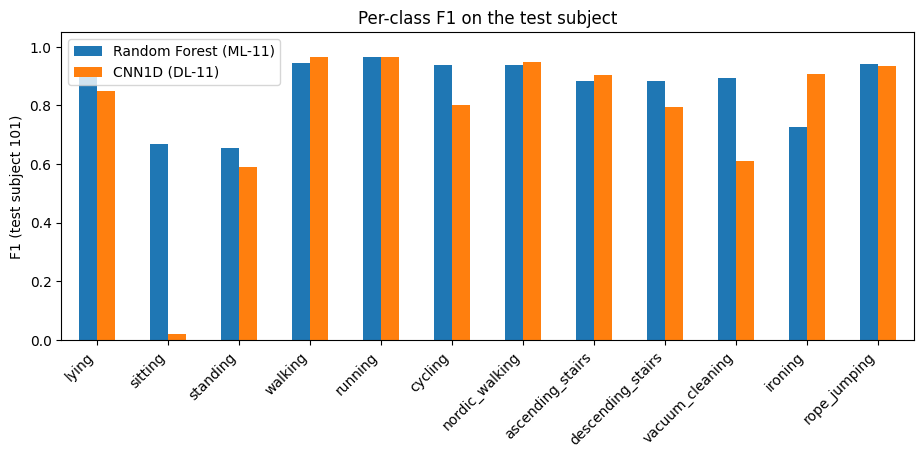

,Random Forest (ML-11),CNN1D (DL-11)
lying,0.929,0.848
sitting,0.669,0.019
standing,0.656,0.589
walking,0.945,0.964
running,0.966,0.966
cycling,0.938,0.800
nordic_walking,0.937,0.947
ascending_stairs,0.882,0.902
descending_stairs,0.883,0.796
vacuum_cleaning,0.894,0.610


In [29]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import learning_curve
from sklearn.base import clone

proba_rf = best_rf.predict_proba(F_test_s)
proba_dl = best_dl.predict(DL_INPUTS[BEST_DL][1], verbose=0)
pred_rf, pred_dl = proba_rf.argmax(1), proba_dl.argmax(1)
FINAL = [("Random Forest (ML-11)", proba_rf, pred_rf), (f"{BEST_DL_NAME} ({BEST_DL})", proba_dl, pred_dl)]

final = pd.DataFrame({name: compute_metrics(y_test, p) for name, p, _ in FINAL}).T.round(4)
final.to_csv(os.path.join(WORK, "results", "final_test_metrics.csv"))
display(final)

per_class = pd.DataFrame({name: f1_score(y_test, pr, average=None) for name, _, pr in FINAL},
                         index=CLASS_NAMES).round(3)
per_class.to_csv(os.path.join(WORK, "results", "final_per_class_f1.csv"))
per_class.plot(kind="bar", figsize=(11, 4))
plt.ylabel("F1 (test subject 101)"); plt.title("Per-class F1 on the test subject")
plt.xticks(rotation=45, ha="right"); plt.ylim(0, 1.05)
save_fig("final_per_class_f1.png"); plt.show()
per_class

In [30]:
# Per-class precision and recall on the test subject
for tag, (name, _, pr) in zip(["rf", "dl"], FINAL):
    rep = pd.DataFrame(classification_report(y_test, pr, target_names=CLASS_NAMES,
                                             output_dict=True, zero_division=0)).T
    rep.to_csv(os.path.join(WORK, "results", f"final_classification_report_{tag}.csv"))
    print(name)
    display(rep.round(3))

Random Forest (ML-11)


,precision,recall,f1-score,support
lying,1.000,0.867,0.929,211.000
sitting,0.710,0.632,0.669,182.000
standing,0.705,0.613,0.656,168.000
walking,0.994,0.901,0.945,172.000
running,1.000,0.933,0.966,165.000
cycling,0.926,0.951,0.938,183.000
nordic_walking,0.979,0.898,0.937,157.000
ascending_stairs,0.897,0.868,0.882,121.000
descending_stairs,0.978,0.805,0.883,113.000
vacuum_cleaning,0.889,0.899,0.894,178.000


CNN1D (DL-11)


,precision,recall,f1-score,support
lying,0.994,0.739,0.848,211.000
sitting,0.083,0.011,0.019,182.000
standing,0.431,0.929,0.589,168.000
walking,1.000,0.930,0.964,172.000
running,1.000,0.933,0.966,165.000
cycling,0.690,0.951,0.800,183.000
nordic_walking,0.980,0.917,0.947,157.000
ascending_stairs,0.888,0.917,0.902,121.000
descending_stairs,0.677,0.965,0.796,113.000
vacuum_cleaning,0.883,0.466,0.610,178.000


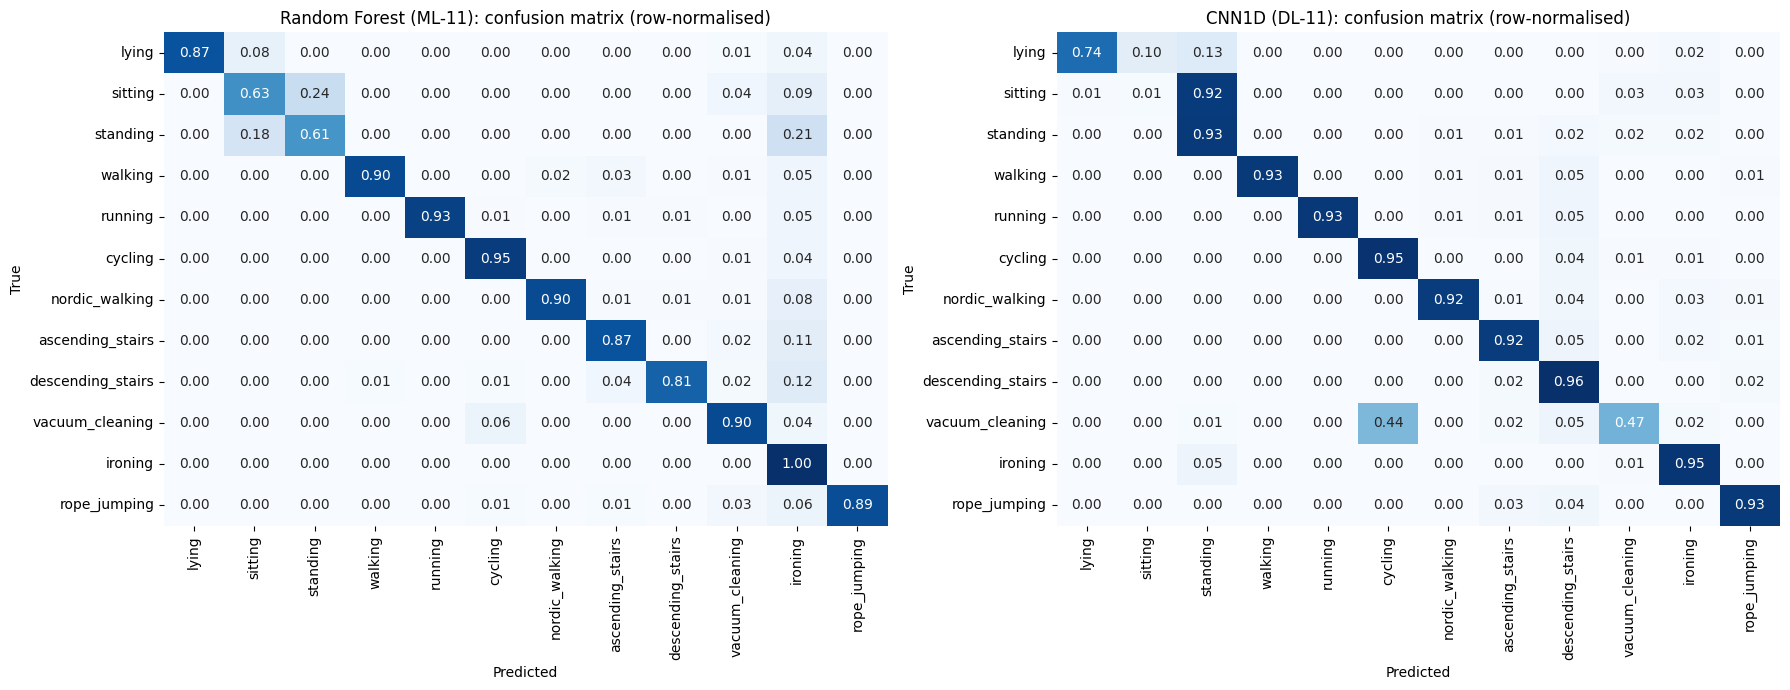

Random Forest (ML-11)


,true,predicted,windows
0,sitting,standing,43
1,standing,ironing,35
2,standing,sitting,30
3,lying,sitting,17
4,sitting,ironing,17
5,descending_stairs,ironing,14


CNN1D (DL-11)


,true,predicted,windows
0,sitting,standing,168
1,vacuum_cleaning,cycling,78
2,lying,standing,27
3,lying,sitting,22
4,vacuum_cleaning,descending_stairs,9
5,ironing,standing,9


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (name, _, pr) in zip(axes, FINAL):
    cm = confusion_matrix(y_test, pr, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}: confusion matrix (row-normalised)")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); save_fig("final_confusion_matrices.png"); plt.show()

def top_confusions(y_true, y_pred, k=6):
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)
    pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]))
             for i in range(N_CLASSES) for j in range(N_CLASSES) if cm[i, j] > 0]
    return pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:k], columns=["true", "predicted", "windows"])

for name, _, pr in FINAL:
    print(name); display(top_confusions(y_test, pr))

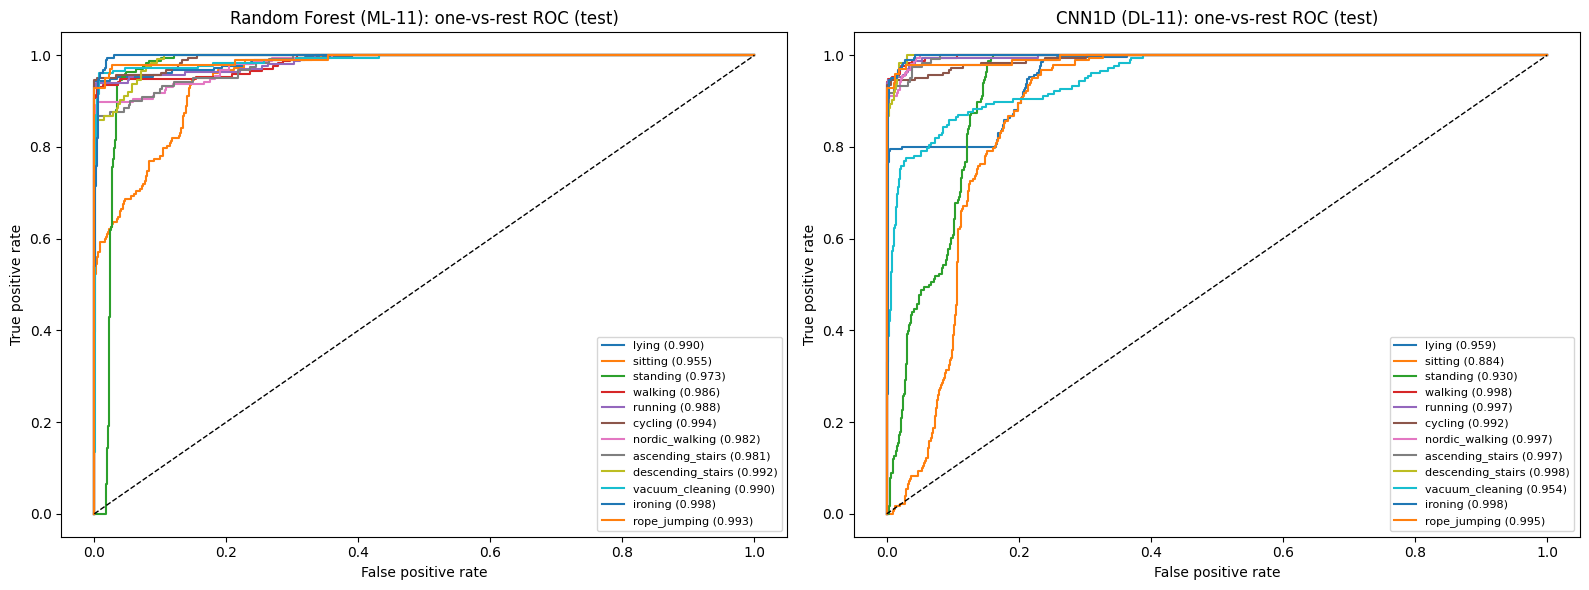

In [32]:
Y_bin = label_binarize(y_test, classes=range(N_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, p, _) in zip(axes, FINAL):
    for c in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(Y_bin[:, c], p[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} ({auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{name}: one-vs-rest ROC (test)")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); save_fig("final_roc_curves.png"); plt.show()

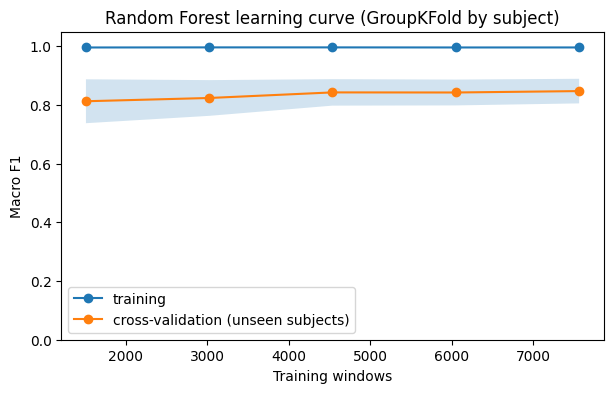

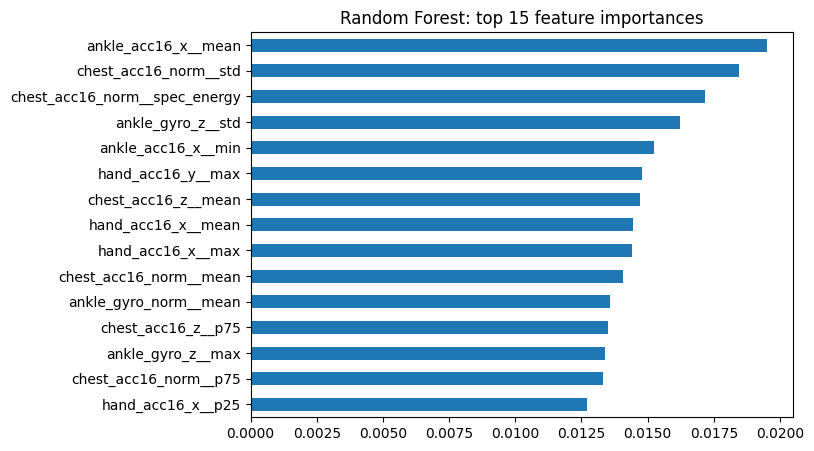

In [33]:
# Learning curve for the Random Forest: how performance changes with more training data
sizes, tr_scores, cv_scores = learning_curve(
    clone(best_rf), F_train_s, y_train, groups=groups_train, cv=GroupKFold(n_splits=3),
    train_sizes=np.linspace(0.2, 1.0, 5), scoring="f1_macro",
    shuffle=True, random_state=SEED, n_jobs=1)

plt.figure(figsize=(7, 4))
plt.plot(sizes, tr_scores.mean(1), "o-", label="training")
plt.plot(sizes, cv_scores.mean(1), "o-", label="cross-validation (unseen subjects)")
plt.fill_between(sizes, cv_scores.mean(1) - cv_scores.std(1), cv_scores.mean(1) + cv_scores.std(1), alpha=0.2)
plt.xlabel("Training windows"); plt.ylabel("Macro F1"); plt.ylim(0, 1.05)
plt.title("Random Forest learning curve (GroupKFold by subject)")
plt.legend(); save_fig("lc_random_forest.png"); plt.show()

imp = pd.Series(best_rf.feature_importances_, index=FEATURE_NAMES_S).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(7, 5))
plt.title("Random Forest: top 15 feature importances")
save_fig("rf_feature_importance.png"); plt.show()

### 10.1 Robustness Check: Leave-One-Subject-Out
The test result above comes from a single person. To check whether the ML vs DL conclusion holds across people, both final configurations are retrained 8 times, each time holding out one subject and training on the other 7. Hyperparameters are frozen (no new tuning).

- **Traditional ML:** the tuned Random Forest configuration (ML-11), and the same configuration on orientation-free features only (ML-12, Section 9.8).
- **Deep learning:** the best orientation-free CNN configuration (highest validation macro F1 among experiments on the magnitude + heart-rate input). Normalisation statistics and class weights are recomputed on each training fold, and it trains for a fixed number of epochs (its best epoch found earlier), since the held-out subject cannot be used for early stopping.
- Macro F1 is computed over the classes each held-out subject actually performed.

**Caveat:** subjects 101–108 were all involved in model selection earlier (training, validation, or cross-validation folds), so this is a consistency check across people, not a fully independent estimate.

LOSO deep learning config: DL-11 {'filters': (64, 64, 128), 'kernel': 3, 'dropout': 0.3} | lr: 0.001 | epochs: 26
Subject 101: RF=0.868  RF-orientation-free=0.781  CNN=0.755
Subject 102: RF=0.885  RF-orientation-free=0.746  CNN=0.755
Subject 103: RF=0.922  RF-orientation-free=0.848  CNN=0.809
Subject 104: RF=0.885  RF-orientation-free=0.807  CNN=0.793
Subject 105: RF=0.906  RF-orientation-free=0.816  CNN=0.814
Subject 106: RF=0.808  RF-orientation-free=0.820  CNN=0.788
Subject 107: RF=0.921  RF-orientation-free=0.779  CNN=0.802
Subject 108: RF=0.898  RF-orientation-free=0.825  CNN=0.834


model,1D CNN (DL-11),RF orientation-free (ML-12),Random Forest
subject,,,
101,0.755,0.781,0.868
102,0.755,0.746,0.885
103,0.809,0.848,0.922
104,0.793,0.807,0.885
105,0.814,0.816,0.906
106,0.788,0.820,0.808
107,0.802,0.779,0.921
108,0.834,0.825,0.898


accuracy        macro_f1       
                                mean    std     mean    std
model                                                      
1D CNN (DL-11)                 0.808  0.033    0.794  0.028
RF orientation-free (ML-12)    0.815  0.038    0.803  0.032
Random Forest                  0.899  0.026    0.887  0.037

Subjects where RF beats CNN: 8 of 8
Subjects where orientation-free RF beats CNN: 5 of 8


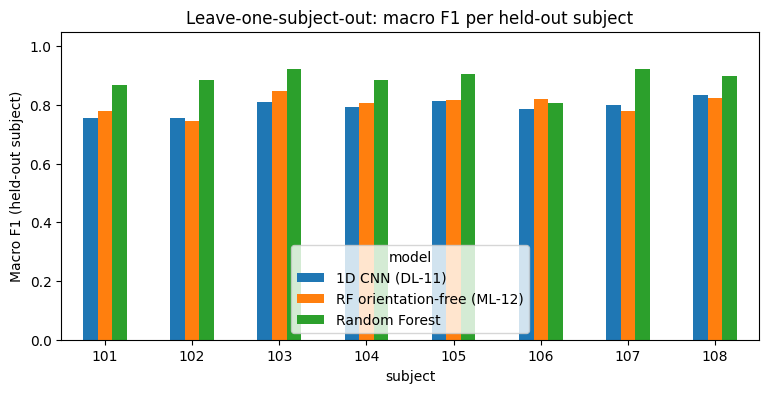

In [34]:
from sklearn.base import clone

res_idx = pd.read_csv(RESULTS_CSV).set_index("exp_id")
res_idx["input"] = res_idx["params"].apply(lambda p: json.loads(p).get("input", ""))
cand = res_idx[(res_idx.index.str.startswith("DL")) & (res_idx["input"] == "norms_6ch+hr")
               & (res_idx["model"] == "CNN1D")]
LOSO_DL = cand["macro_f1"].idxmax()
bp = json.loads(res_idx.loc[LOSO_DL, "params"])
cnn_cfg = dict(filters=tuple(int(f) for f in str(bp["filters"]).split("-")),
               kernel=int(bp["kernel"]), dropout=float(bp["dropout"]))
cnn_lr = float(bp["lr"])
best_epochs = int(np.argmin(histories[LOSO_DL].history["val_loss"])) + 1
DL_LABEL = f"1D CNN ({LOSO_DL})"
print("LOSO deep learning config:", LOSO_DL, cnn_cfg, "| lr:", cnn_lr, "| epochs:", best_epochs)

# Features and orientation-free channels for ALL windows (same order as y_win / s_win)
F_all = np.zeros((len(y_win), F_train_s.shape[1]), dtype=np.float32)
F_all[train_mask], F_all[val_mask], F_all[test_mask] = F_train_s, F_val_s, F_test_s
XN_all = np.concatenate([norm_channels(X_win),
                         X_win[:, :, [SENSOR_COLS.index("heart_rate")]]], axis=2).astype(np.float32)

rows = []
for s in sorted(np.unique(s_win)):
    tr, te = s_win != s, s_win == s
    present = np.unique(y_win[te])

    rf = clone(best_rf).fit(F_all[tr], y_win[tr])
    p_rf = rf.predict(F_all[te])
    rf_of = clone(best_rf).fit(F_all[tr][:, ORI_FREE], y_win[tr])
    p_rf_of = rf_of.predict(F_all[te][:, ORI_FREE])

    mu_f = XN_all[tr].mean((0, 1), keepdims=True)
    sd_f = XN_all[tr].std((0, 1), keepdims=True) + 1e-8
    X_tr_f = ((XN_all[tr] - mu_f) / sd_f).astype(np.float32)
    X_te_f = ((XN_all[te] - mu_f) / sd_f).astype(np.float32)
    cw_f = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_win[tr])))

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    cnn = build_cnn(X_tr_f.shape[1:], **cnn_cfg)
    cnn.compile(optimizer=tf.keras.optimizers.Adam(cnn_lr),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cnn.fit(make_ds_fn(X_tr_f, y_win[tr], True), epochs=best_epochs, class_weight=cw_f, verbose=0)
    p_cnn = cnn.predict(X_te_f, verbose=0).argmax(1)

    for name, p in [("Random Forest", p_rf), ("RF orientation-free (ML-12)", p_rf_of), (DL_LABEL, p_cnn)]:
        rows.append({"subject": s, "model": name, "n_windows": int(te.sum()), "n_classes": len(present),
                     "accuracy": accuracy_score(y_win[te], p),
                     "macro_f1": f1_score(y_win[te], p, labels=present, average="macro")})
    print(f"Subject {s}: RF={rows[-3]['macro_f1']:.3f}  RF-orientation-free={rows[-2]['macro_f1']:.3f}  CNN={rows[-1]['macro_f1']:.3f}")

loso = pd.DataFrame(rows)
loso.to_csv(os.path.join(WORK, "results", "loso_results.csv"), index=False)
loso_pivot = loso.pivot(index="subject", columns="model", values="macro_f1")
display(loso_pivot.round(3))
display(loso.groupby("model")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(3))
print("Subjects where RF beats CNN:", int((loso_pivot["Random Forest"] > loso_pivot[DL_LABEL]).sum()), "of", len(loso_pivot))
print("Subjects where orientation-free RF beats CNN:",
      int((loso_pivot["RF orientation-free (ML-12)"] > loso_pivot[DL_LABEL]).sum()), "of", len(loso_pivot))

loso_pivot.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Macro F1 (held-out subject)"); plt.ylim(0, 1.05); plt.xticks(rotation=0)
plt.title("Leave-one-subject-out: macro F1 per held-out subject")
save_fig("loso_comparison.png"); plt.show()

**Interpretation.** The tuned Random Forest beats the CNN on every held-out subject in the reference run (8 of 8), with mean macro F1 0.887 ± 0.037 versus about 0.80 ± 0.03 for the CNN. The gap varies by person: it is smallest for subject 106, who is also the hardest subject for the Random Forest (0.808), and largest for subject 107. Test subject 101 (RF 0.868) is slightly harder than average, so the single-subject test result in Section 10 was, if anything, a little pessimistic for the Random Forest.

Compare the orientation-free Random Forest (ML-12) with the CNN to see how much of the gap is due to the **model** and how much to the **input information**: if ML-12 scores close to the CNN, the advantage comes mostly from posture information in the features; if ML-12 still beats the CNN clearly, the Random Forest is also the better model for this amount of data.

### 10.2 Error Analysis
*Numbers below are from the reference run; the RF results are deterministic, while deep learning results can vary slightly between GPU runs.*

**Confusion patterns.** Random Forest errors concentrate among low-movement postures: sitting ↔ standing (24% / 18%) and standing → ironing (21%). Ironing acts as a "sink" class: recall 1.00 but low precision (F1 0.73), because ironing is standing with small arm movements, so ambiguous still windows fall into it. Per-class precision and recall confirm it: ironing has recall 1.00 but precision 0.57. The CNN's dominant errors are sitting → standing (about 90% of sitting windows), vacuum cleaning → cycling (more than half of vacuum-cleaning windows), and, in the reference run, lying → sitting or standing (lying recall about 0.5). The CNN's lying score also changed noticeably between GPU runs, which shows how unstable still postures are without orientation information. The CNN is better than the Random Forest on ironing, a repetitive arm rhythm that convolutions over time capture well.

**Why the CNN fails on posture.** The CNN uses only magnitude channels, which removed orientation-related overfitting (Section 9.5) but also removed the direction of gravity. When a person is still, acceleration magnitude is ~9.8 m/s² regardless of posture, so sitting and standing look nearly identical. The Random Forest's most important feature is `ankle_acc16_x__mean`, the direction of gravity on the ankle, which is exactly the information the CNN cannot see. This is a direct trade-off: orientation-free inputs generalise across people but lose posture.

**ROC vs F1.** AUC stays high even where F1 is low (e.g., RF sitting: AUC 0.955, F1 0.67). AUC measures whether the true class is ranked highly; F1 depends on it being ranked first. For classes that share signal characteristics, the model ranks correctly but splits probability between them.

**Bias–variance.** The Random Forest learning curve shows training F1 ≈ 1.0 and cross-validation F1 rising slowly from 0.81 to 0.85, with a persistent gap of ~0.15 and a ±0.05 spread across held-out subjects. This is a high-variance pattern: the model fits the training people well but does not fully transfer. More windows from the same six subjects give small gains; more subjects would likely help more. The CNN on raw axes (DL-02 to DL-05) showed the extreme version of this, which regularisation could not fix because the cause was a systematic difference between subjects (sensor placement), not noise.

### 10.3 Limitations
- Only 8 usable subjects; a single test subject gives a noisy estimate, which is why Section 10.1 repeats the comparison across all subjects.
- Rope jumping and running were not performed by every subject, so their training data comes from fewer people.
- Sensor placement differs between subjects (Section 9.5), and the dataset contains no information to correct it.

### 10.4 Future Work
- Add the chest sensor's raw axes back to the CNN input: the orientation diagnostic showed the chest sensor is consistent across subjects, so it could restore posture information without reintroducing wrist/ankle orientation problems. (Not tested here, to avoid model selection on the test subject.)
- Orientation-normalisation of raw axes (e.g., rotating each recording so gravity aligns with a fixed axis).
- Collect or add data from more subjects, since the learning curve indicates variance across people is the main limit.

## 11. Conclusion
On subjects the models have never seen, a tuned Random Forest on engineered features outperformed the best deep learning model: macro F1 0.864 versus about 0.74 on test subject 101, and higher on all 8 subjects in leave-one-subject-out validation (mean 0.887 versus about 0.80). The largest gains came from input representation and feature selection, not model complexity: removing magnetometer features improved the Random Forest by about 0.05 macro F1, switching the CNN to orientation-free inputs raised it from about 0.35 to about 0.87 on validation, and CNN hyperparameter changes moved it by less than 0.02. Orientation-free inputs made the CNN generalise across people but removed the posture information needed to separate sitting, standing and lying. With only a handful of training subjects, hand-designed features that keep posture information generalised better than features learned from raw signals.

In [35]:
# Write requirements.txt with the exact versions used in this run
import matplotlib, seaborn, joblib, tensorboard
reqs = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
        "tensorflow": tf.__version__, "tensorboard": tensorboard.__version__,
        "matplotlib": matplotlib.__version__, "seaborn": seaborn.__version__, "joblib": joblib.__version__}
with open(os.path.join(WORK, "requirements.txt"), "w") as f:
    f.write("\n".join(f"{k}=={v}" for k, v in reqs.items()) + "\n")
print(open(os.path.join(WORK, "requirements.txt")).read())

for d in ["models", "results", "figures", "logs"]:
    p = os.path.join(WORK, d)
    print(d, sorted(os.listdir(p))[:12])

numpy==2.1.3
pandas==2.3.3
scikit-learn==1.6.1
tensorflow==2.20.0
tensorboard==2.20.0
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0

models ['best_dl_model.h5', 'best_dl_model.keras', 'best_random_forest.joblib', 'dl_norm_channel_stats.npz', 'dl_norm_stats.npz', 'rf_metadata.json']
results ['experiment_table.csv', 'experiments.csv', 'final_classification_report_dl.csv', 'final_classification_report_rf.csv', 'final_per_class_f1.csv', 'final_test_metrics.csv', 'loso_results.csv', 'rf_tuning_cv.csv']
figures ['diag_sensor_orientation.png', 'eda_class_distribution.png', 'eda_signal_examples.png', 'eda_subject_activity.png', 'final_confusion_matrices.png', 'final_per_class_f1.png', 'final_roc_curves.png', 'lc_DL-01.png', 'lc_DL-02.png', 'lc_DL-03.png', 'lc_DL-04.png', 'lc_DL-05.png']
logs ['DL-01', 'DL-02', 'DL-03', 'DL-04', 'DL-05', 'DL-06', 'DL-07', 'DL-08', 'DL-09', 'DL-10', 'DL-11', 'DL-12']
